In [1]:
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd
import seaborn as sns
from nmfprofiler.nmfprofiler import NMFProfiler
from numpy.linalg import multi_dot
from sklearn.utils.extmath import safe_sparse_dot

from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report, accuracy_score
from sklearn import metrics
from sklearn.preprocessing import MinMaxScaler
from statannotations.Annotator import Annotator
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

from tqdm import tqdm

In [2]:
cna_df_raw = pd.read_csv("/Users/andrearosini/Desktop/python/full diamond/Full_colorectal_data/diamond_cna_colorectal_andrea.csv")
meth_df_raw = pd.read_csv("/Users/andrearosini/Desktop/python/full diamond/Full_colorectal_data/diamond_meth_colorectal_andrea.csv")
# cna_df_raw = pd.read_csv("/Users/andrearosini/Desktop/python/mini diamond dataset/diamond_cna_subset_andrea.csv")
# meth_df_raw = pd.read_csv("/Users/andrearosini/Desktop/python/mini diamond dataset/diamond_meth_subset_andrea.csv")

In [3]:
cna_df = cna_df_raw[["chr", "Label", "zscore"]]
meth_df = meth_df_raw.drop(columns=["Metastasis_status", "Stage", "Age.range", "Sex"])
sample = cna_df["Label"].unique()
chr = cna_df["chr"][0:44]
chr[np.arange(0, 44, 2)] = chr[np.arange(0, 44, 2)]+ "_w1"
chr[np.arange(1, 44,2)] = chr[np.arange(1, 44,2)]+ "_w2"
cna_df = pd.DataFrame(cna_df["zscore"].to_numpy().reshape(cna_df["zscore"].to_numpy().size // 44, 22*2), columns = chr)
cna_df.insert(0, "Label", sample)
cna_df.set_index("Label", inplace=True)
cna_df = cna_df.reindex(meth_df["sample"]).reset_index()

feature_name = ["CG#" + str(i) for i in range(1, 30+1)] 
meth_df.drop(columns = meth_df.filter(like = "_h"), inplace=True)
#cna_df.drop(columns = ["chr13_w1, chr14_w1"])
meth_df.columns = ["sample", "Cohorte", "biological_class"] + feature_name

cna_df_disc = cna_df[meth_df["Cohorte"] == "Discovery"]
meth_df_disc = meth_df[meth_df["Cohorte"] == "Discovery"]
cna_df_valid = cna_df[meth_df["Cohorte"] == "Validation"]
meth_df_valid = meth_df[meth_df["Cohorte"] == "Validation"]

In [4]:
chr_cols = cna_df.filter(like = "chr").columns
cg_cols = meth_df.filter(like = "CG").columns
cna_df = cna_df.reindex(sorted(chr_cols, key = lambda x: int(x.replace("chr", " ").replace("w", ""))), axis = 1)
chr_cols = cna_df.filter(like = "chr").columns

healthy_row = meth_df.index[meth_df.biological_class == "healthy"]
cancer_row = meth_df.index[meth_df.biological_class != "healthy"]
disc_row = meth_df.index[meth_df.Cohorte == "Discovery"]
valid_row = meth_df.index[meth_df.Cohorte != "Discovery"]
healthy_row_disc = meth_df_disc.index[meth_df_disc.biological_class == "healthy"]
cancer_row_disc = meth_df_disc.index[meth_df_disc.biological_class != "healthy"]
healthy_row_valid = meth_df_valid.index[(meth_df_valid.biological_class == "healthy")]
cancer_row_valid = meth_df_valid.index[(meth_df_valid.biological_class != "healthy")]

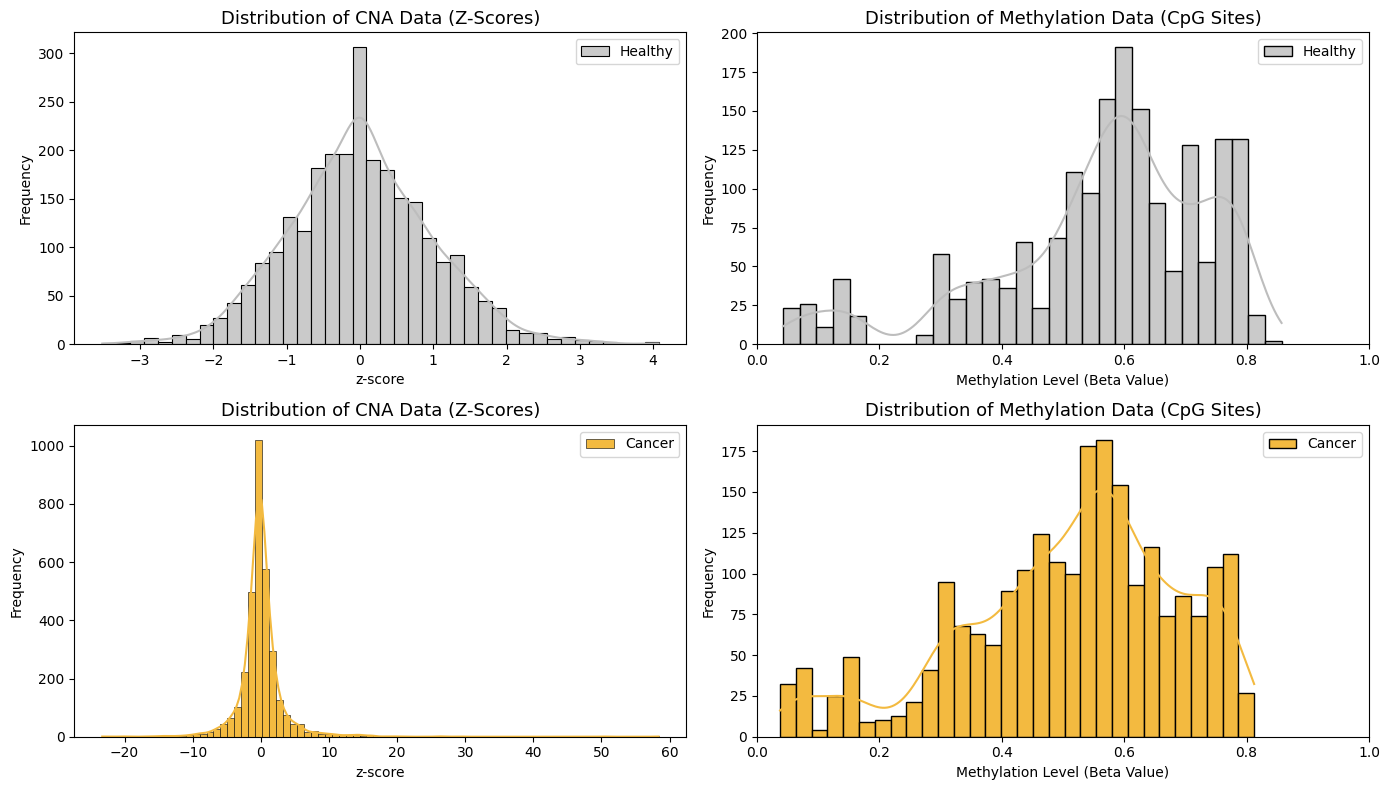

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. Distribuzione dei dati cromosomici (zscore)
sns.histplot(cna_df[chr_cols].iloc[healthy_row_disc].to_numpy().flatten(), kde=True, ax=axes[0,0], color="#BDBDBD", bins=40, alpha=0.8, label='Healthy', legend=True)
sns.histplot(cna_df[chr_cols].iloc[cancer_row_disc].to_numpy().flatten(), kde=True, ax=axes[1,0], color='#F3BA40', bins=80, alpha=1, label='Cancer', legend=True)

axes[0,0].set_title("Distribution of CNA Data (Z-Scores)", fontsize=13)
axes[0,0].set_xlabel("z-score")
axes[0,0].set_ylabel("Frequency")
#axes[0,0].set_xbound([-5, 5])
axes[1,0].set_title("Distribution of CNA Data (Z-Scores)", fontsize=13)
axes[1,0].set_xlabel("z-score")
axes[1,0].set_ylabel("Frequency")
#axes[1,0].set_xbound([-10, 10])

# 2. Distribuzione globale dei siti di metilazione cg
sns.histplot(meth_df[cg_cols].iloc[healthy_row_disc].to_numpy().flatten(), bins = 30, ax=axes[0,1], kde=True, color="#BDBDBD", label='Healthy', alpha = 0.8, legend=True)
sns.histplot(meth_df[cg_cols].iloc[cancer_row_disc].to_numpy().flatten(), bins = 30, ax=axes[1,1], kde = True, color='#F3BA40', label='Cancer', alpha = 1, legend=True)
axes[0,1].set_xlim(0, 1)
axes[1,1].set_xlim(0, 1)
axes[0,1].set_title("Distribution of Methylation Data (CpG Sites)", fontsize=13)
axes[0,1].set_xlabel("Methylation Level (Beta Value)")
axes[0,1].set_ylabel("Frequency")

axes[1,1].set_title("Distribution of Methylation Data (CpG Sites)", fontsize=13)
axes[1,1].set_xlabel("Methylation Level (Beta Value)")
axes[1,1].set_ylabel("Frequency")

axes[0,0].legend()
axes[1,0].legend()
axes[0,1].legend()
axes[1,1].legend()

plt.tight_layout()
plt.show()

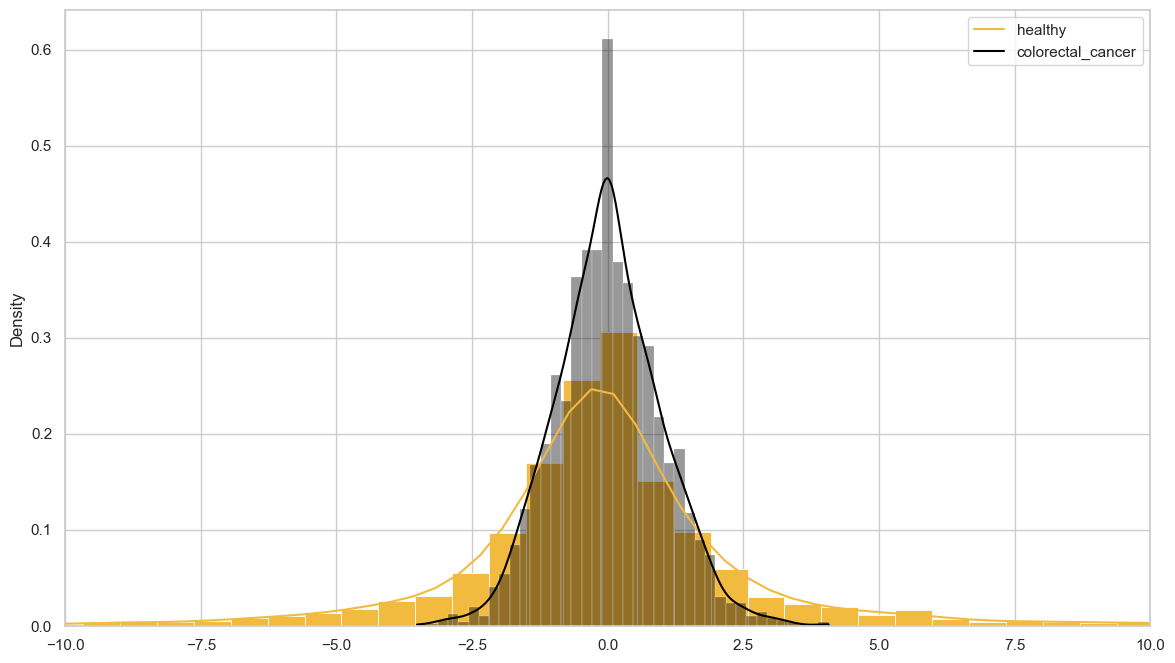

In [1135]:
fig, axes = plt.subplots(1, 1, figsize=(14, 8))
sns.histplot(cna_df[chr_cols].iloc[cancer_row_disc].to_numpy().flatten(), kde=True, ax=axes, color='#F3BA40', bins=120, alpha=1, label='Cancer', legend=True, stat = "density")
sns.histplot(cna_df[chr_cols].iloc[healthy_row_disc].to_numpy().flatten(), kde=True, ax=axes, color="black", bins=40, alpha=0.4, label='Healthy', legend=True, stat = "density")
axes.legend(["healthy", "colorectal_cancer"])
axes.set_xlim([-10, 10])
plt.show()

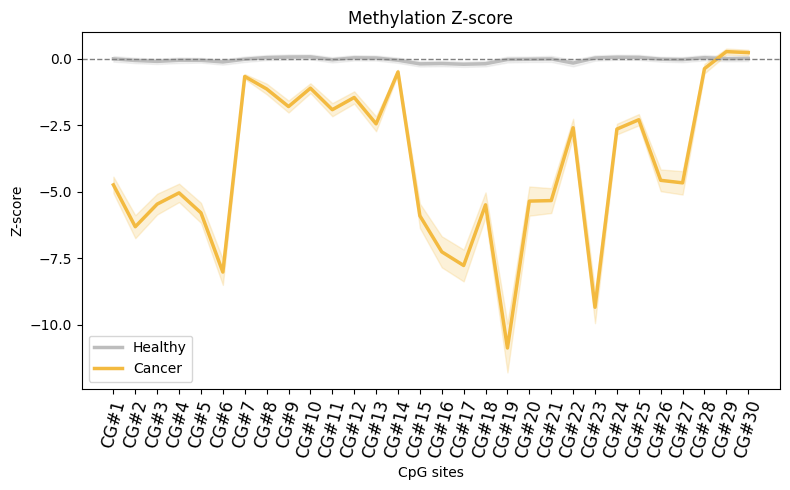

In [7]:

baseline_healthy = np.random.choice(healthy_row, size = 50,  replace = False)
mean_meth_healthy = meth_df.loc[baseline_healthy, cg_cols].mean(axis=0)
sd_meth_healthy = meth_df.loc[baseline_healthy, cg_cols].std(axis=0)
z_score_meth_healthy = (meth_df.loc[healthy_row, cg_cols] - mean_meth_healthy) / sd_meth_healthy
z_score_meth_cancer = (meth_df.loc[cancer_row, cg_cols] - mean_meth_healthy) / sd_meth_healthy
z_score_meth = (meth_df[cg_cols] - mean_meth_healthy) / sd_meth_healthy

fig, ax = plt.subplots(figsize=(8, 5))

for data, label, color in [
    (z_score_meth_healthy, "Healthy","#BDBDBD"),
    (z_score_meth_cancer, "Cancer", "#F3BA40"),
]:
    mean = data.mean(axis=0)
    std = data.std(axis=0)
    x = np.arange(len(mean))

    ax.plot(x, mean.to_numpy(), color=color, linewidth=2.5, label=f"{label}")
    ax.fill_between(
        x,
        (mean - 0.1*std).to_numpy(),
        (mean + 0.1*std).to_numpy(),
        color=color,
        alpha=0.2,
    )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Methylation Z-score")
ax.set_xlabel("CpG sites")
ax.set_ylabel("Z-score")
ax.legend()
ax.set_yticks(np.arange(0, -11, -2.5))
ax.set_xticks(np.arange(len(feature_name)))
ax.set_xticklabels(feature_name, rotation=75, fontsize=12)
plt.tight_layout()
plt.show()

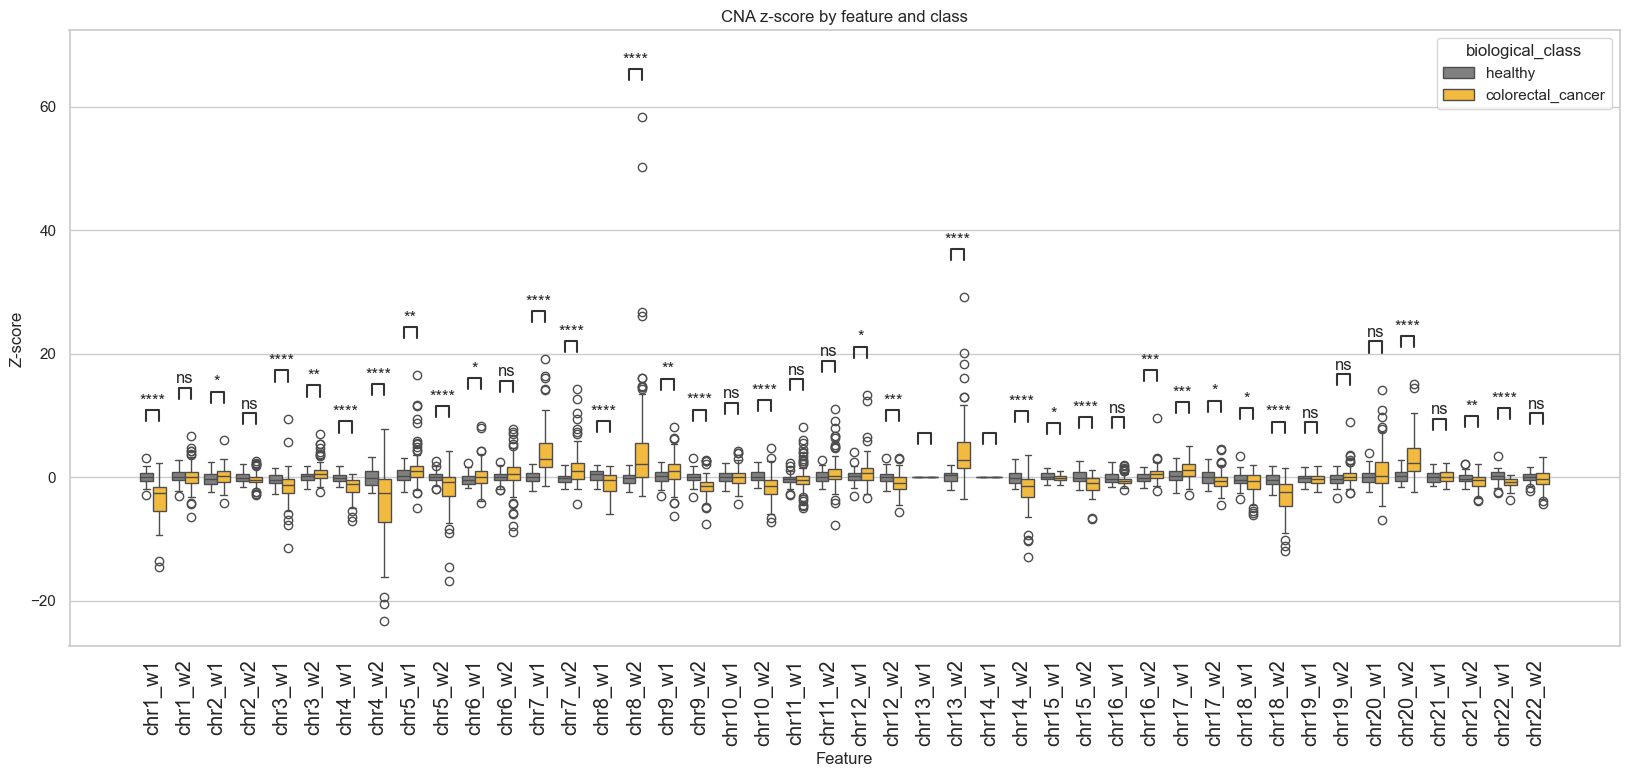

In [ ]:
cna_df["biological_class"] = meth_df["biological_class"]
cna_long = cna_df.iloc[disc_row, 0::].drop(columns = "mean_z").melt(
    id_vars="biological_class", var_name="Feature", value_name="Z-score"
)
meth_long = meth_df.iloc[disc_row, 2::].drop(columns = ["mean_methylation", "mean_meth"]).melt(
    id_vars="biological_class", var_name = "Feature", value_name="Methylation", ignore_index=True,
)

fig, axes = plt.subplots(1, 1, figsize = (20, 8))

sns.boxplot(
    data=cna_long, x="Feature", y="Z-score", hue="biological_class",
    hue_order=["healthy", "colorectal_cancer"],
    palette={"healthy": "grey", "colorectal_cancer": "#F3BA40"},
    ax=axes,
    saturation=1
)
axes.tick_params(axis="x", rotation=90, labelsize = 'large')
axes.set_title("CNA z-score by feature and class")


class_order = ["healthy", "colorectal_cancer"]

def annotate_features(ax, data, y_col):
    features = data["Feature"].dropna().unique().tolist()
    pairs = [
        ((feature, "healthy"), (feature, "colorectal_cancer"))
        for feature in features
    ]

    annotator = Annotator(
        ax,
        pairs,
        data=data,
        x="Feature",
        y=y_col,
        hue="biological_class",
        order=features,
        hue_order=class_order,
    )
    annotator.configure(
        test="Mann-Whitney",
        text_format="star",
        loc="inside",
        #comparisons_correction="Benjamini-Hochberg",
        verbose=0,
    )
    annotator.apply_and_annotate()

    return len(pairs)

n_cna = annotate_features(axes, cna_long, "Z-score")



#plt.tight_layout()

plt.show()

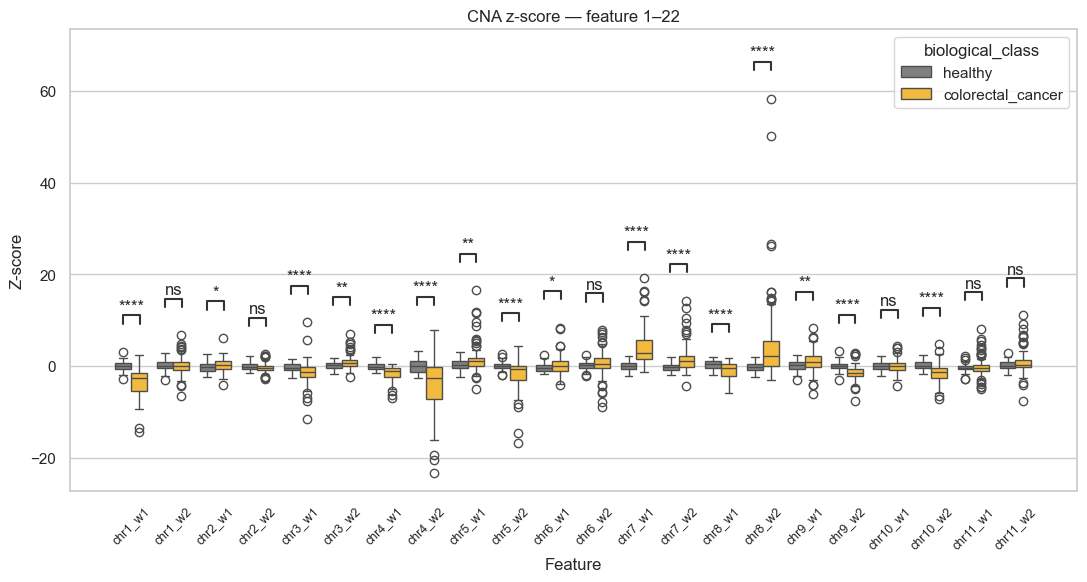

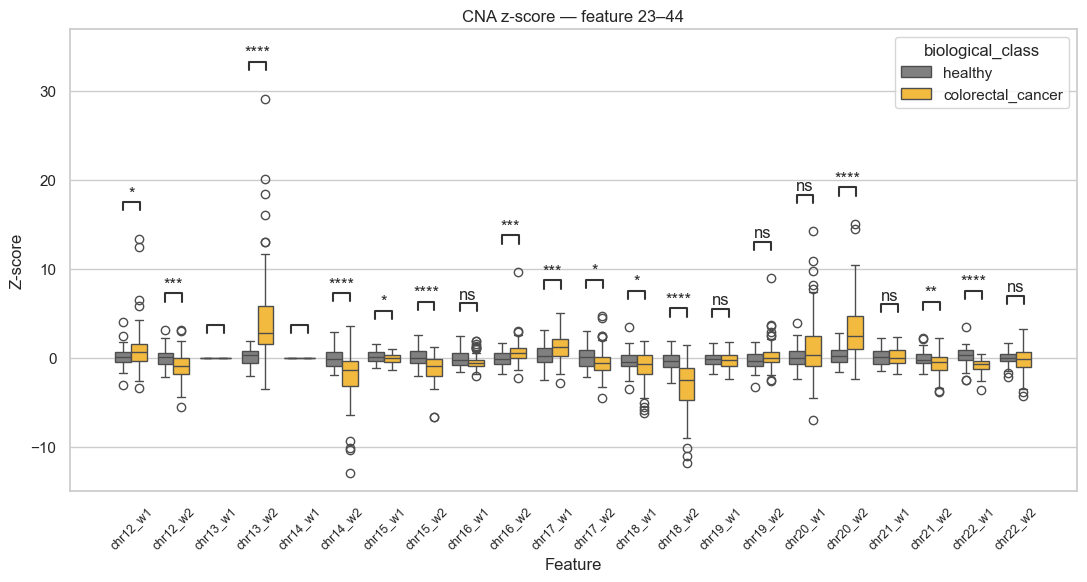

In [1165]:
features = cna_long["Feature"].dropna().unique().tolist()

for start in range(0, len(features), 22):
    order = features[start:start + 22]
    data_part = cna_long[cna_long["Feature"].isin(order)]

    fig, ax = plt.subplots(figsize=(13, 6))
    sns.boxplot(
        data=data_part,
        x="Feature",
        y="Z-score",
        hue="biological_class",
        order=order,
        hue_order=class_order,
        palette={"healthy": "grey", "colorectal_cancer": "#F3BA40"},
        width=0.75,
        ax=ax,
        saturation=1
    )
    ax.tick_params(axis="x", rotation=45, labelsize=9)
    ax.set_title(f"CNA z-score — feature {start + 1}–{start + len(order)}")

    annotate_features(ax, data_part, "Z-score")
    #fig.tight_layout()
    plt.show()

Comparazioni CNA: 44; comparazioni meth: 30


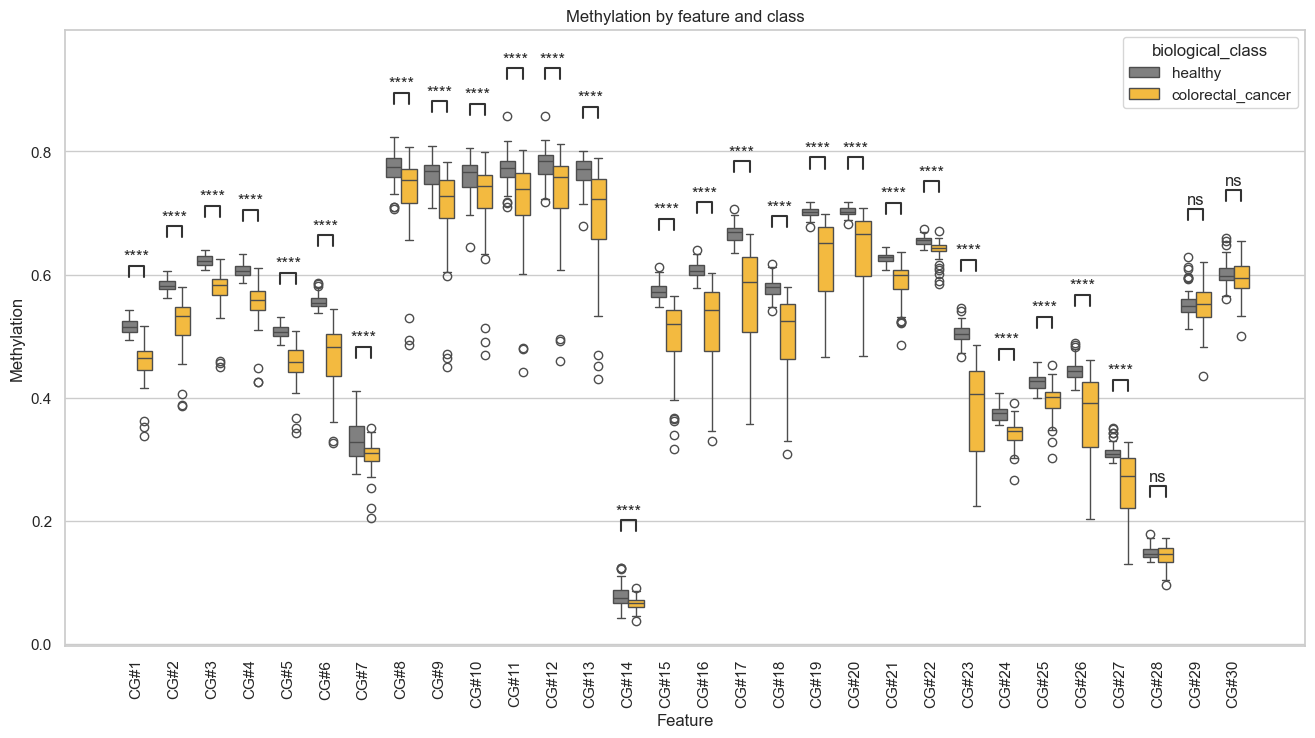

In [1155]:
fig, axes = plt.subplots(1, 1, figsize = (16, 8))

sns.boxplot(
    data=meth_long, x="Feature", y="Methylation", hue="biological_class",
    hue_order=["healthy", "colorectal_cancer"],
    palette={"healthy": "grey", "colorectal_cancer": "#F3BA40"},
    ax=axes,
    saturation=1
)

axes.tick_params(axis="x", rotation=90)
axes.set_title("Methylation by feature and class")
n_meth = annotate_features(axes, meth_long, "Methylation")

print(f"Comparazioni CNA: {n_cna}; comparazioni meth: {n_meth}")


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

colorectal_cancer vs. healthy: Mann-Whitney-Wilcoxon test two-sided, P_val:1.097e-04 U_stat=4.102e+06
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

colorectal_cancer vs. healthy: Mann-Whitney-Wilcoxon test two-sided, P_val:5.024e-31 U_stat=3.920e+02


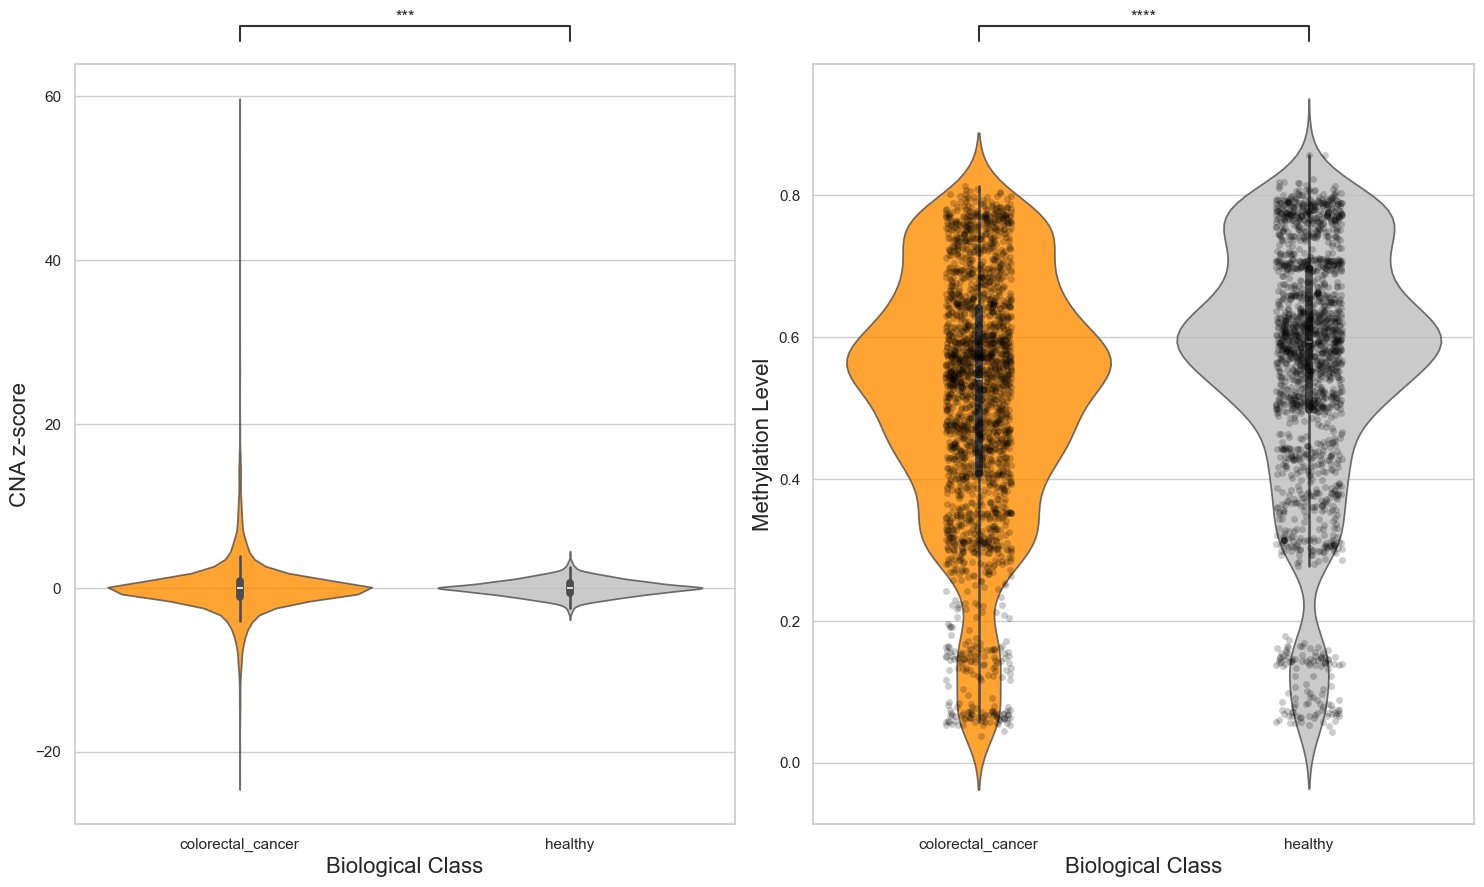

In [1136]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9))

sns.violinplot(data=cna_long, x='biological_class', y='Z-score', hue='biological_class', ax=axes[0], 
               palette={"healthy": "#BDBDBD", "colorectal_cancer": "darkorange"}, legend=False, alpha = 0.8, saturation=1)
axes[0].set_xlabel("Biological Class", fontsize=16)
axes[0].set_ylabel("CNA z-score", fontsize=16)
pairs = [("colorectal_cancer", "healthy")]

meth_df['mean_methylation'] = meth_df[cg_cols].mean(axis=1)
meth_copy = meth_df_disc.copy()
meth_copy = meth_copy.melt(id_vars=['sample', 'biological_class'], value_vars=cg_cols, var_name='CpG_site', value_name='methylation_level')

sns.violinplot(data=meth_copy, x='biological_class', y='methylation_level', hue='biological_class', ax=axes[1],
                palette={"healthy": "#BDBDBD", "colorectal_cancer": "darkorange"}, legend=False, alpha = 0.8, saturation=1)
sns.stripplot(data=meth_copy, x='biological_class', y='methylation_level', color='black', alpha=0.2, ax=axes[1])
#axes[1].set_title("Livello medio metilazione CpG: Controlli sani vs Tumore", fontsize=13)
#axes[1].set_xlabel("Classe Biologica")
#axes[1].set_ylabel("Media siti CpG")
axes[1].set_xlabel("Biological Class", 
                   fontsize=16)
axes[1].set_ylabel("Methylation Level", fontsize=16)
pairs = [("colorectal_cancer", "healthy")]

annotator = Annotator(
    axes[0], pairs, data=cna_long, x = 'biological_class', y='Z-score'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside")
annotator.apply_and_annotate()

annotator = Annotator(
    axes[1], pairs, data=meth_df, x = 'biological_class', y='mean_methylation'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside")
annotator.apply_and_annotate()


plt.tight_layout()
plt.show()


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

colorectal_cancer vs. healthy: Mann-Whitney-Wilcoxon test two-sided, P_val:6.770e-04 U_stat=8.655e+05
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

colorectal_cancer vs. healthy: Mann-Whitney-Wilcoxon test two-sided, P_val:5.024e-31 U_stat=3.920e+02


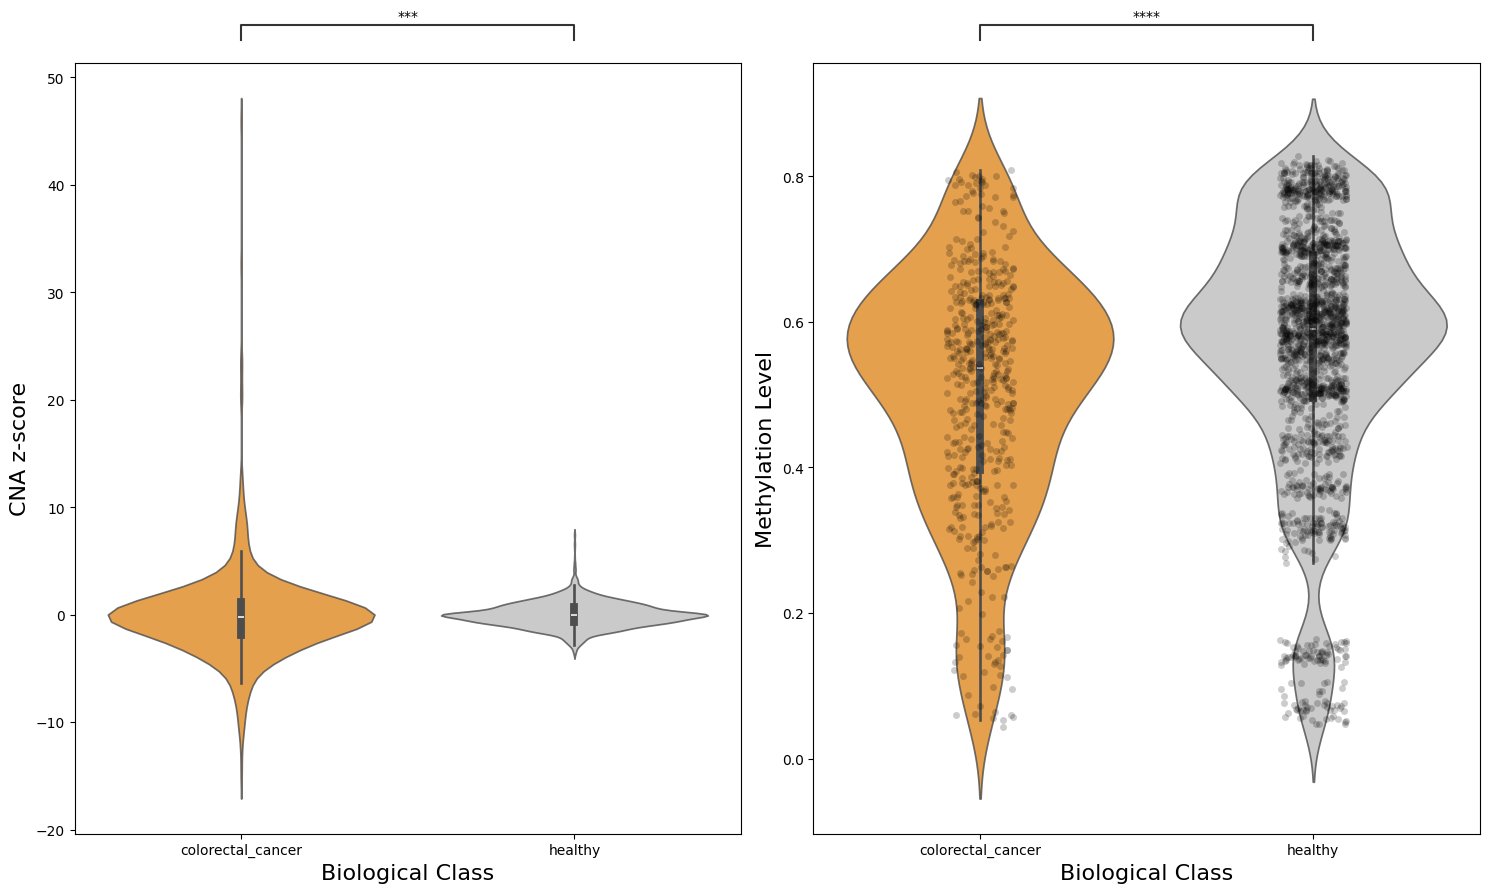

In [10]:
cna_df_valid["biological_class"] = meth_df_valid["biological_class"]
cna_long_2 = cna_df_valid[cna_df_valid.columns[2:]].melt(
    id_vars="biological_class", var_name="Feature", value_name="Z-score"
)
meth_long_2 = meth_df_valid.iloc[:, 2::].melt(
    id_vars="biological_class", var_name = "Feature", value_name="Methylation", ignore_index=True,
)



fig, axes = plt.subplots(1, 2, figsize=(15, 9))

sns.violinplot(data=cna_long_2, x='biological_class', y='Z-score', hue='biological_class', ax=axes[0], 
               palette={"healthy": "#BDBDBD", "colorectal_cancer": "darkorange"}, legend=False, alpha = 0.8)
axes[0].set_xlabel("Biological Class", fontsize=16)
axes[0].set_ylabel("CNA z-score", fontsize=16)
pairs = [("colorectal_cancer", "healthy")]

meth_df['mean_methylation'] = meth_df[cg_cols].mean(axis=1)
meth_copy_2 = meth_df_valid.copy()
meth_copy_2 = meth_copy_2.melt(id_vars=['sample', 'biological_class'], value_vars=cg_cols, var_name='CpG_site', value_name='methylation_level')

sns.violinplot(data=meth_copy_2, x='biological_class', y='methylation_level', hue='biological_class', ax=axes[1],
                palette={"healthy": "#BDBDBD", "colorectal_cancer": "darkorange"}, legend=False, alpha = 0.8)
sns.stripplot(data=meth_copy_2, x='biological_class', y='methylation_level', color='black', alpha=0.2, ax=axes[1])

axes[1].set_xlabel("Biological Class", 
                   fontsize=16)
axes[1].set_ylabel("Methylation Level", fontsize=16)
pairs = [("colorectal_cancer", "healthy")]

annotator = Annotator(
    axes[0], pairs, data=cna_long_2, x = 'biological_class', y='Z-score'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside")
annotator.apply_and_annotate()

annotator = Annotator(
    axes[1], pairs, data=meth_df, x = 'biological_class', y='mean_methylation'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside")
annotator.apply_and_annotate()


plt.tight_layout()
plt.show()


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Discovery vs. Validation: Mann-Whitney-Wilcoxon test two-sided, P_val:3.136e-01 U_stat=6.708e+05


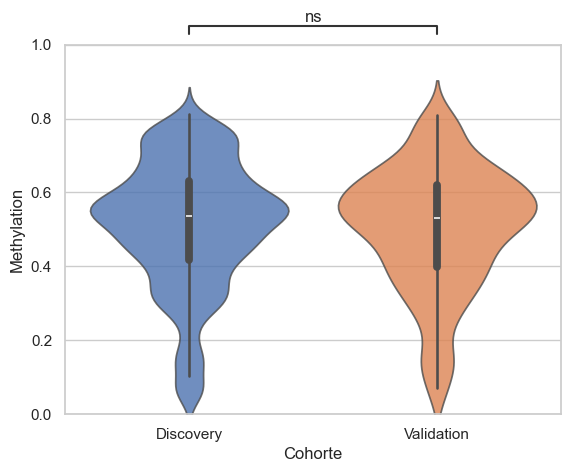

In [1149]:
# Comparing validation and discovery datasets for methylation levels:
fig,  axes = plt.subplots(1,1)

meth_long_total = meth_df.iloc[cancer_row_disc.append(cancer_row_valid)].drop(columns=['biological_class']).iloc[:, 1::].melt(
    id_vars="Cohorte", var_name = "Feature", value_name="Methylation", ignore_index=True,
)

pairs = [("Discovery", "Validation")]

annotator = Annotator(
    axes, pairs, data=meth_long_total, x = 'Cohorte', y='Methylation'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside")
annotator.apply_and_annotate()



sns.violinplot(data=meth_long_total, x='Cohorte', y='Methylation', hue='Cohorte', legend=False, alpha = 0.8, saturation=1)
#sns.stripplot(data=cna, x='Cohorte', y='methylation_level', color='black', alpha=0.2, ax=axes[1]) 


plt.show()               

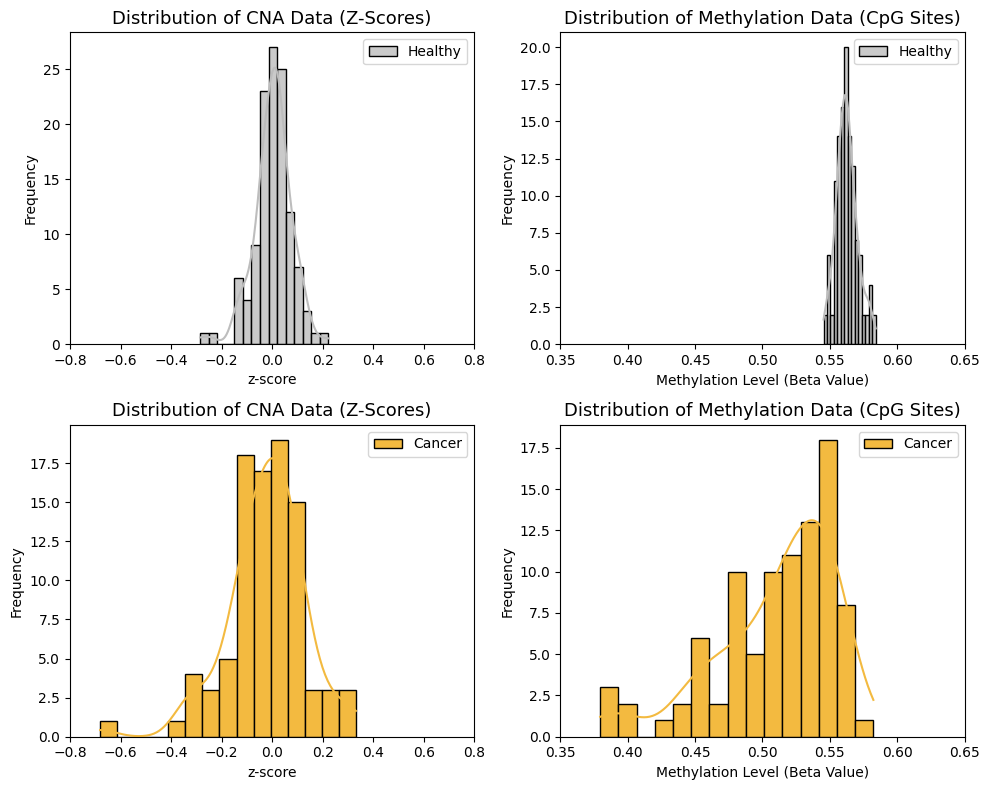

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10,8))

cna_df["mean_z"] = cna_df[chr_cols].mean(axis=1)
meth_df["mean_meth"] = meth_df[cg_cols].mean(axis=1)

sns.histplot(cna_df.loc[healthy_row, "mean_z"], kde=True, ax=axes[0,0], color="#BDBDBD", bins=15, alpha=0.8, label='Healthy', legend=True)
sns.histplot(cna_df.loc[cancer_row, "mean_z"], kde=True, ax=axes[1,0], color='#F3BA40', bins=15, alpha=1, label='Cancer', legend=True)

axes[0,0].set_title("Distribution of CNA Data (Z-Scores)", fontsize=13)
axes[0,0].set_xlabel("z-score")
axes[0,0].set_ylabel("Frequency")
axes[0, 0].set_xlim([-0.8, 0.8])
axes[1, 0].set_xlim([-0.8, 0.8])
#axes[0,0].set_xbound([-5, 5])
axes[1,0].set_title("Distribution of CNA Data (Z-Scores)", fontsize=13)
axes[1,0].set_xlabel("z-score")
axes[1,0].set_ylabel("Frequency")
#axes[1,0].set_xbound([-10, 10])

# 2. Distribuzione globale dei siti di metilazione cg
sns.histplot(meth_df.loc[healthy_row, "mean_meth"].to_numpy().flatten(), bins = 15, ax=axes[0,1], kde=True, color="#BDBDBD", label='Healthy', alpha = 0.8, legend=True)
sns.histplot(meth_df.loc[cancer_row, "mean_meth"].to_numpy().flatten(), bins = 15, ax=axes[1,1], kde = True, color='#F3BA40', label='Cancer', alpha = 1, legend=True,)
axes[0, 1].set_xlim([0.35, 0.65])
axes[1, 1].set_xlim([0.35, 0.65])
axes[0,1].set_title("Distribution of Methylation Data (CpG Sites)", fontsize=13)
axes[0,1].set_xlabel("Methylation Level (Beta Value)")
axes[0,1].set_ylabel("Frequency")

axes[1,1].set_title("Distribution of Methylation Data (CpG Sites)", fontsize=13)
axes[1,1].set_xlabel("Methylation Level (Beta Value)")
axes[1,1].set_ylabel("Frequency")

axes[0,0].legend()
axes[1,0].legend()
axes[0,1].legend()
axes[1,1].legend()

plt.tight_layout()
plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

colorectal_cancer vs. healthy: Mann-Whitney-Wilcoxon test two-sided with Benjamini-Hochberg correction, P_val:1.097e-04 U_stat=4.102e+06


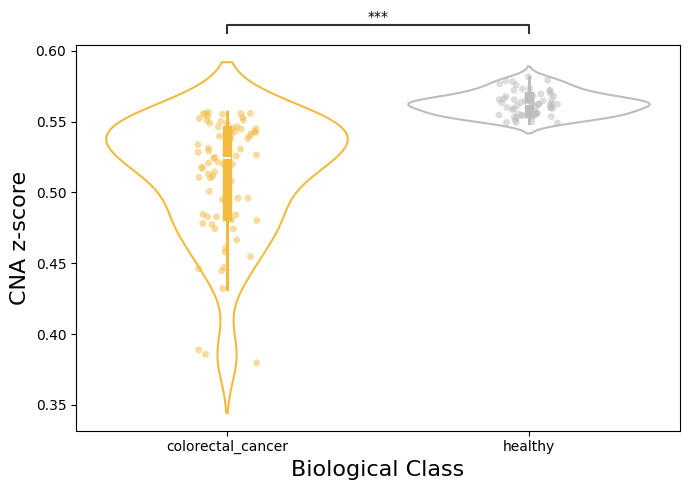

In [13]:
fig, axes = plt.subplots(1, 1, figsize=(7, 5))

sns.violinplot(data = meth_df.loc[disc_row,["mean_meth", "biological_class"]], x = "biological_class", y = "mean_meth", hue = "biological_class", ax=axes, 
               palette={"healthy": "#BDBDBD", "colorectal_cancer": "#F3BA40"}, legend=False, alpha = 1.0, fill=False, saturation=1)
sns.stripplot(data=meth_df.loc[disc_row, ["mean_meth", "biological_class" ]], x='biological_class', y='mean_meth', hue="biological_class", alpha=0.5, 
                palette={"healthy": "#BDBDBD", "colorectal_cancer": "#F3BA40"}, )

axes.set_xlabel("Biological Class", fontsize=16)
axes.set_ylabel("CNA z-score", fontsize=16)
pairs = [("colorectal_cancer", "healthy")]

annotator = Annotator(
    axes, pairs, data=cna_long, x = 'biological_class', y='Z-score'
)
annotator.configure(test="Mann-Whitney", text_format="star", loc="outside", comparisons_correction="Benjamini-Hochberg")
annotator.apply_and_annotate()

plt.tight_layout()
plt.show()


In [871]:
# Clipping of z-scores
cna_signed = cna_df[chr_cols].clip(lower=-100, upper = 100)
meth_signed = meth_df[cg_cols].clip(lower=-30, upper = 30)


# Separating postive values from negatives
chr = chr_cols.to_numpy()
chr = np.repeat(chr, 2)
cna_gain = cna_signed.clip(lower=0)
cna_loss = (-cna_signed).clip(lower=0)
cna_gain.columns = chr[np.arange(0, 88, 2)]+ "_pos"
cna_loss.columns = chr[np.arange(1, 88, 2)]+ "_neg"
cna_signed = pd.concat([cna_gain, cna_loss], axis=1)
cna_signed = cna_signed.reindex(sorted(cna_signed.columns, key = lambda x: int(x.replace("chr", " ").replace("w", "").replace("_pos", "").replace("_neg", ""))), axis = 1)

# Separating postive values from negatives
# cg = cg_cols.to_numpy()
# cg = np.repeat(cg, 2)
# meth_gain = meth_signed.clip(lower=0)
# meth_loss = (-meth_signed).clip(lower=0)
# meth_gain.columns = cg[np.arange(0, 60, 2)]+ "_pos"
# meth_loss.columns = cg[np.arange(1, 60, 2)]+ "_neg"
# meth_signed = pd.concat([meth_gain, meth_loss], axis=1)
# meth_signed = meth_signed.reindex(sorted(meth_signed.columns, key = lambda x: int(x.replace("CG#", "").replace("_pos", "").replace("_neg", ""))), axis = 1)


X1 = meth_df[cg_cols].to_numpy()
X2 = cna_signed.drop(columns=["chr13_w1_pos", "chr14_w1_pos", "chr13_w1_neg", "chr14_w1_neg"]).to_numpy()
#X2 = cna_signed.to_numpy()
#X1 = X1 / X1.max(axis= 0)
#X2 = (X2) / (X2.max(axis = 0))

y = (meth_df.biological_class == "colorectal_cancer").astype(int).to_numpy()

# X1 = (X1-X1.min(axis = 0) ) / (X1.max(axis = 0) - X1.min(axis = 0))
# X2 = (X2-X2.min(axis = 0) ) / (X2.max(axis = 0) - X2.min(axis = 0))
# X1 *= (1 / np.linalg.norm(X1, 'fro'))
# X2 *= (1 / np.linalg.norm(X2, "fro"))

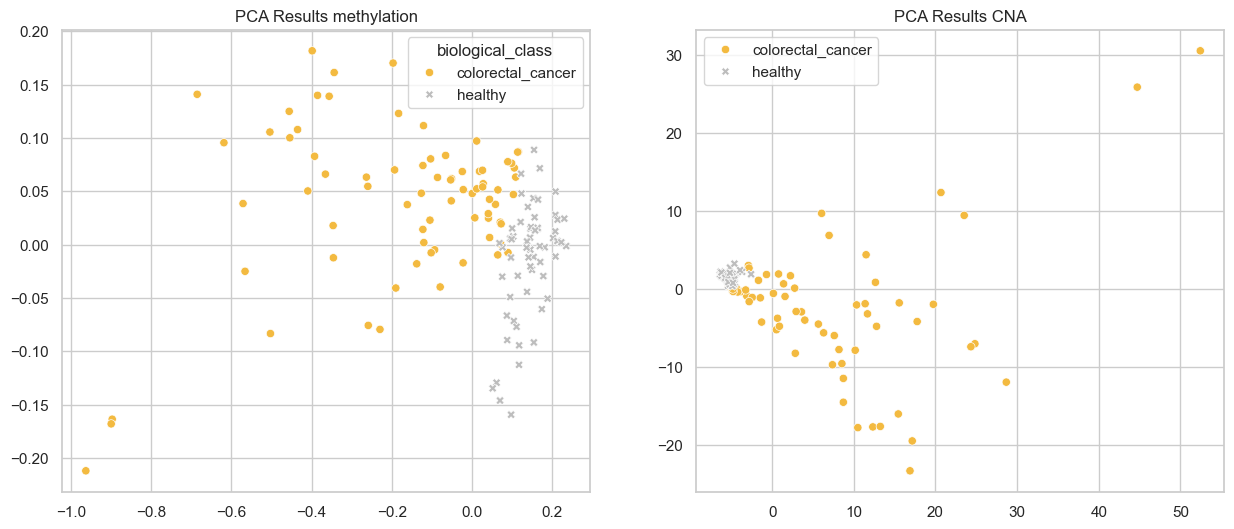

In [569]:
# apply a pca
pca_1 = PCA(n_components=2)
X1_pca = pca_1.fit_transform(X1)
pca_2 = PCA(n_components = 2)
X2_pca = pca_2.fit_transform(X2)
# show pca results and projection dividing data by class

fig, ax = plt.subplots(1, 2,figsize=(15, 6))

sns.scatterplot(x=X1_pca[:, 0], y=X1_pca[:, 1], hue=meth_df['biological_class'], ax=ax[0], 
                palette = {"healthy": "#BDBDBD", "colorectal_cancer": "#F3BA40"}, style=meth_df_disc['biological_class'])
sns.scatterplot(x=X2_pca[:, 0], y=X2_pca[:, 1], hue=meth_df['biological_class'], ax=ax[1], 
                palette = {"healthy": "#BDBDBD", "colorectal_cancer": "#F3BA40"}, style=meth_df[meth_df.Cohorte == "Discovery"]['biological_class'])
ax[0].set_title('PCA Results methylation')
ax[1].set_title('PCA Results CNA')
#plt.title('PCA Results')
plt.legend()
plt.show()

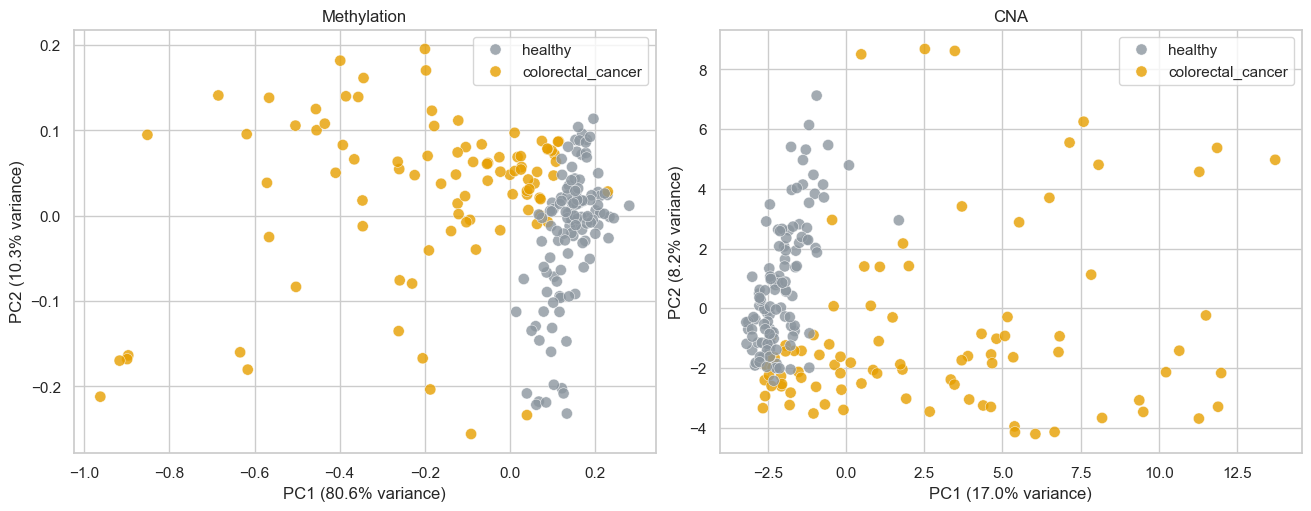

In [1166]:
from sklearn.preprocessing import StandardScaler
# La standardizzazione della methylation dà peso simile a ogni feature.
# Per CNA la ometto perché, come suggerisce il nome della variabile,
# X2 contiene già z-score.
#X_meth_scaled = StandardScaler().fit_transform(X1)
X_meth_scaled = X1
pca_meth = PCA(n_components=2)
meth_scores = pca_meth.fit_transform(X_meth_scaled)

X_cna_scaled = X2
X_cna_scaled = StandardScaler().fit_transform(X2)
pca_cna = PCA(n_components=2)
cna_scores = pca_cna.fit_transform(X_cna_scaled)

sns.set_theme(style="whitegrid", context="notebook")
palette = {
    "healthy": "#8C969F",
    "colorectal_cancer": "#E69F00",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

panels = [
    (axes[0], meth_scores, pca_meth, "Methylation"),
    (axes[1], cna_scores, pca_cna, "CNA"),
]

for ax, scores, pca_model, title in panels:
    sns.scatterplot(
        x=scores[:, 0],
        y=scores[:, 1],
        hue=meth_df.biological_class,
        hue_order=["healthy", "colorectal_cancer"],
        palette=palette,
        s=65,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.4,
        ax=ax,
    )

    variance = pca_model.explained_variance_ratio_ * 100
    ax.set(
        title=title,
        xlabel=f"PC1 ({variance[0]:.1f}% variance)",
        ylabel=f"PC2 ({variance[1]:.1f}% variance)",
    )
    ax.legend(frameon=True)

#sns.despine()
plt.show()

In [17]:
# single omic
# projection and regression

In [1511]:

# X1_train = X1[cancer_row_disc.append(healthy_row_disc)]
# X1_valid = X1[cancer_row_valid.append(healthy_row_valid)]
# X2_train = X2[cancer_row_disc.append(healthy_row_disc)]
# X2_valid = X2[cancer_row_valid.append(healthy_row_valid)]
# y_train = y[cancer_row_disc.append(healthy_row_disc)]
# y_valid = y[cancer_row_valid.append(healthy_row_valid)]

X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, train_size=0.8, stratify = y)
tests = [X1_test, X2_test]    

omics = [X1_train, X2_train]
for j in range(len(omics)):
    for i in range(omics[j].shape[1]):
        tests[j][:, i] = (
                    tests[j][:, i]  - np.min(omics[j][:, i])
                ) / (
                    np.max(omics[j][:, i])- np.min(omics[j][:, i])
                )
        omics[j][:, i] = (
            omics[j][:, i] - np.min(omics[j][:, i])
        ) / (
            np.max(omics[j][:, i]) - np.min(omics[j][:, i]) 
        )
        
    omics[j] = (
        omics[j] * (1 / np.sqrt(omics[j].shape[1]))
    )
    tests[j] = tests[j] * (1 / np.sqrt(omics[j].shape[1]))

In [1522]:
model = NMFProfiler(
    omics=omics,
    y=y_train,
    as_sklearn=True,
    # params={
    #             "gamma":1e-3,
    #             "lambda": 1e-7,
    #             "mu": 1e-7,
    #             "eta": 1.00,
    #             "alpha": 2,
    #             "sigma": 1e-9,
    #             "m_back": 1,
    #         },
    backtrack=True,
    verbose=True)

res = model.fit()


Converting y levels into integers...
Original levels:  [0 1]
New levels:  [0 1] 

Error after initialization step: 257.696379
Epoch 10 reached after 0.017 seconds, error: 108.643415
Epoch 20 reached after 0.029 seconds, error: 103.287063
Epoch 30 reached after 0.042 seconds, error: 101.199809
Epoch 40 reached after 0.053 seconds, error: 99.960942
Epoch 50 reached after 0.064 seconds, error: 99.179989
Epoch 60 reached after 0.076 seconds, error: 98.719486
Epoch 70 reached after 0.089 seconds, error: 98.430203
Epoch 80 reached after 0.101 seconds, error: 98.224930
Epoch 90 reached after 0.114 seconds, error: 98.070813
Epoch 100 reached after 0.126 seconds, error: 97.951193
Algorithm converged in 105 steps                  after 0.132 seconds, error: 97.900968


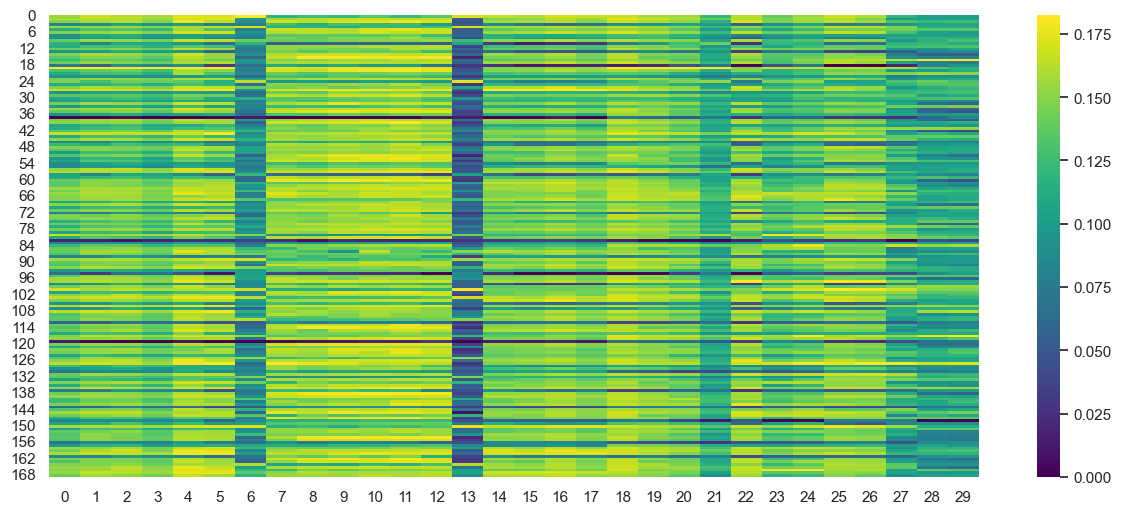

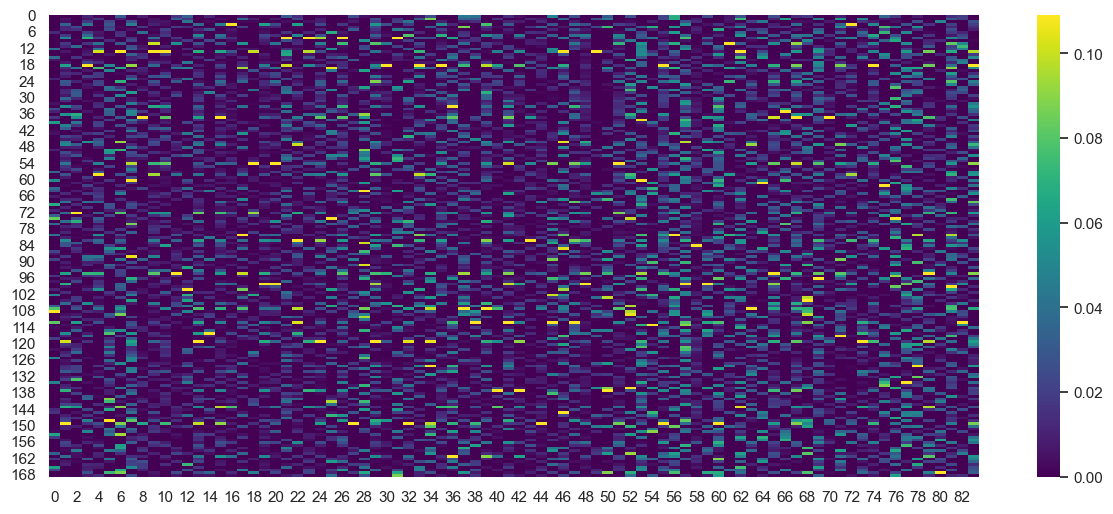

In [1478]:
res.heatmap(obj_to_viz="omic", width=15, height=6, path="", omic_number=1)
res.heatmap(obj_to_viz="omic", width=15, height=6, path="", omic_number=2)

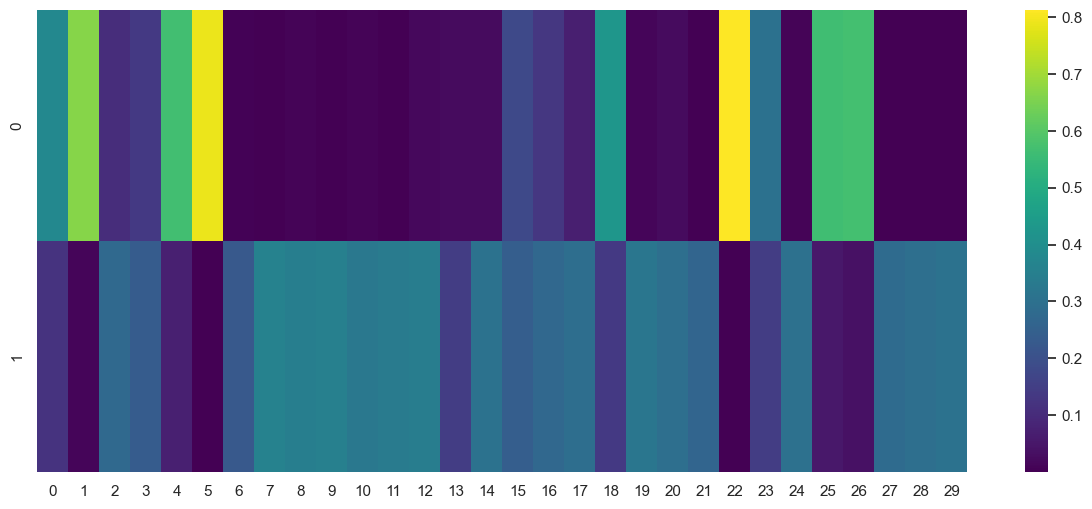

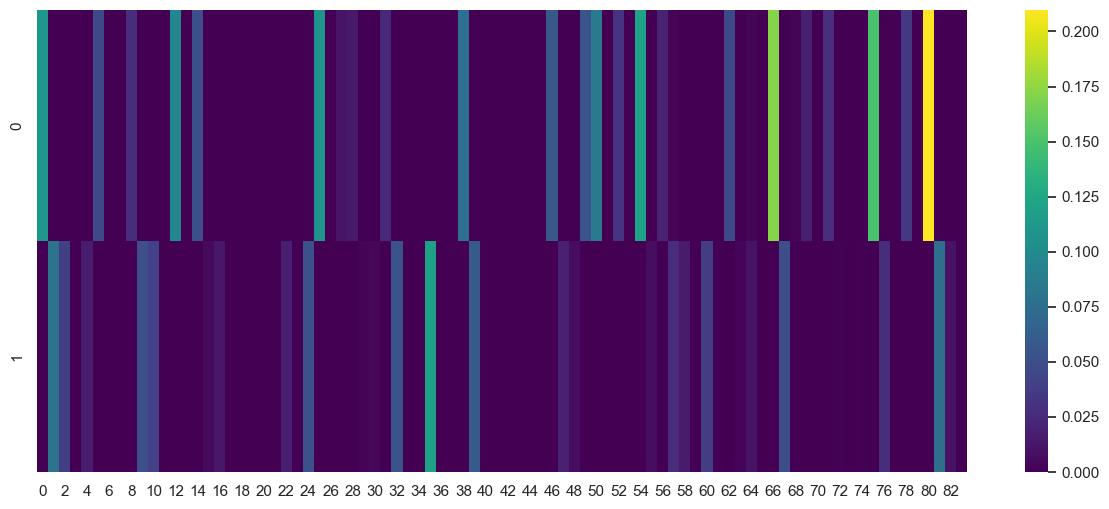

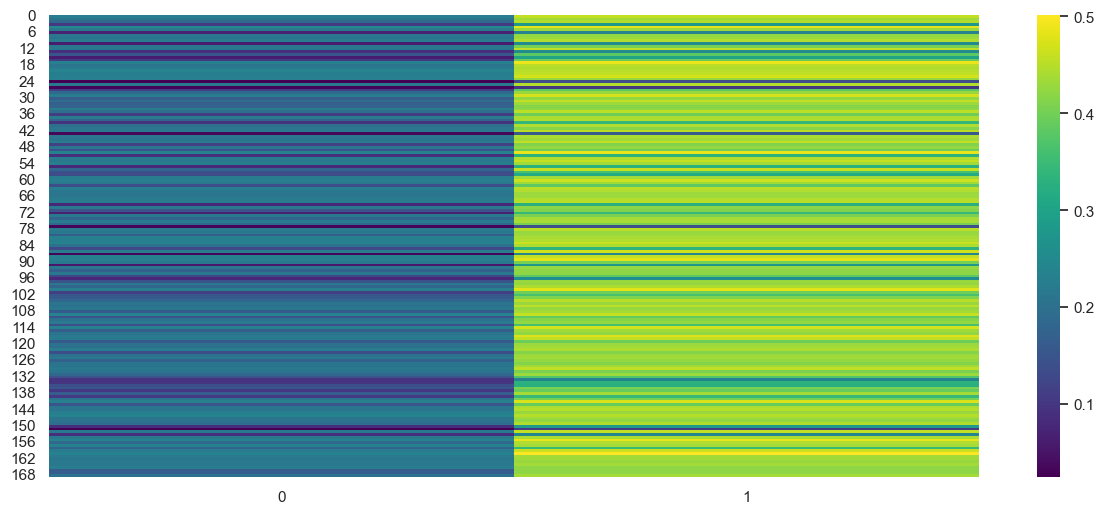

In [1523]:
res.heatmap(obj_to_viz="H", width=15, height=6, path="", omic_number=1)
res.heatmap(obj_to_viz="H", width=15, height=6, path="", omic_number=2)
res.heatmap(obj_to_viz="W", width=15, height=6, path="")

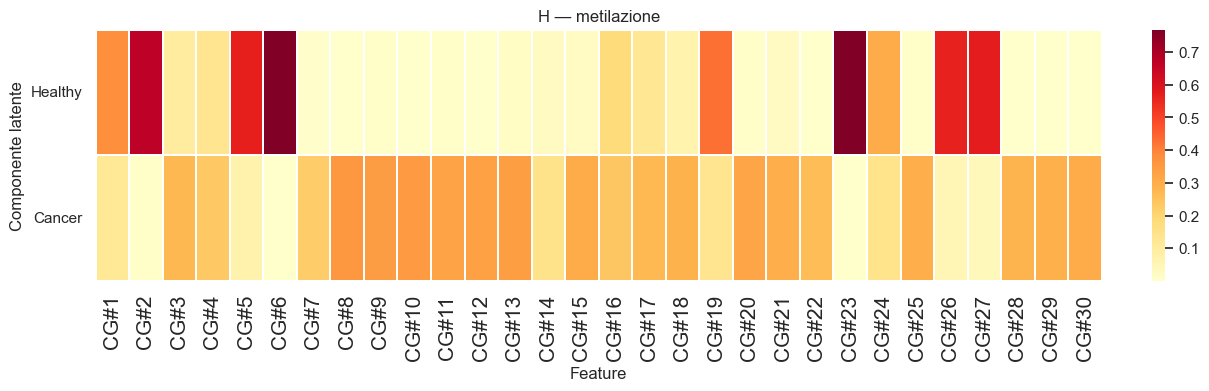

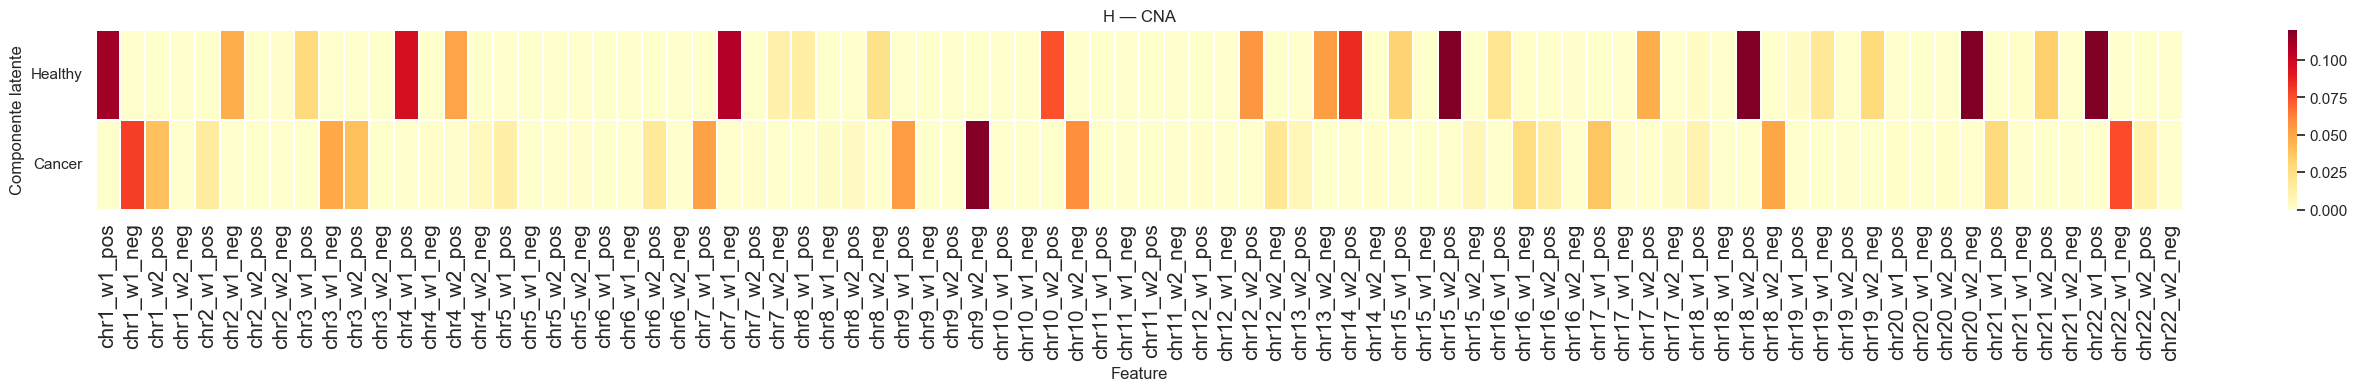

In [1524]:
feature_names = [
    meth_df[cg_cols].columns.to_numpy(),
    cna_signed.drop(columns=[
        "chr13_w1_pos", "chr14_w1_pos",
        "chr13_w1_neg", "chr14_w1_neg",
    ]).columns.to_numpy(),
]

def plot_H(res, omic_idx, names, title):
    H = np.asarray(res.Hs[omic_idx])
    names = np.asarray(names)

    if res.removed_columns is not None:
        names = np.delete(names, res.removed_columns[omic_idx])

    if H.shape[1] != len(names):
        raise ValueError(
            f"H ha {H.shape[1]} colonne ma ci sono {len(names)} etichette."
        )

    rows = ["Healthy", "Cancer"] if H.shape[0] == 2 else [
        f"Componente {i + 1}" for i in range(H.shape[0])
    ]
    table = pd.DataFrame(H, index=rows, columns=names)

    fig, ax = plt.subplots(
        figsize=(max(12, 0.28 * len(names)), 3.8),
        layout="constrained",
    )
    sns.heatmap(
        table,
        ax=ax,
        robust=True,
        cmap='YlOrRd',
        linewidths=0.2,
        linecolor="white",
    )
    ax.set_title(title)
    ax.set_xlabel("Feature")
    ax.set_ylabel("Componente latente")
    ax.tick_params(axis="x", labelrotation=90, labelsize=15)
    ax.tick_params(axis="y", labelrotation=0)

    plt.show()

plot_H(res, 0, feature_names[0], "H — metilazione")
plot_H(res, 1, feature_names[1], "H — CNA")

In [1374]:
Hd = np.max(H[0, :] - H[1, :], 0) 

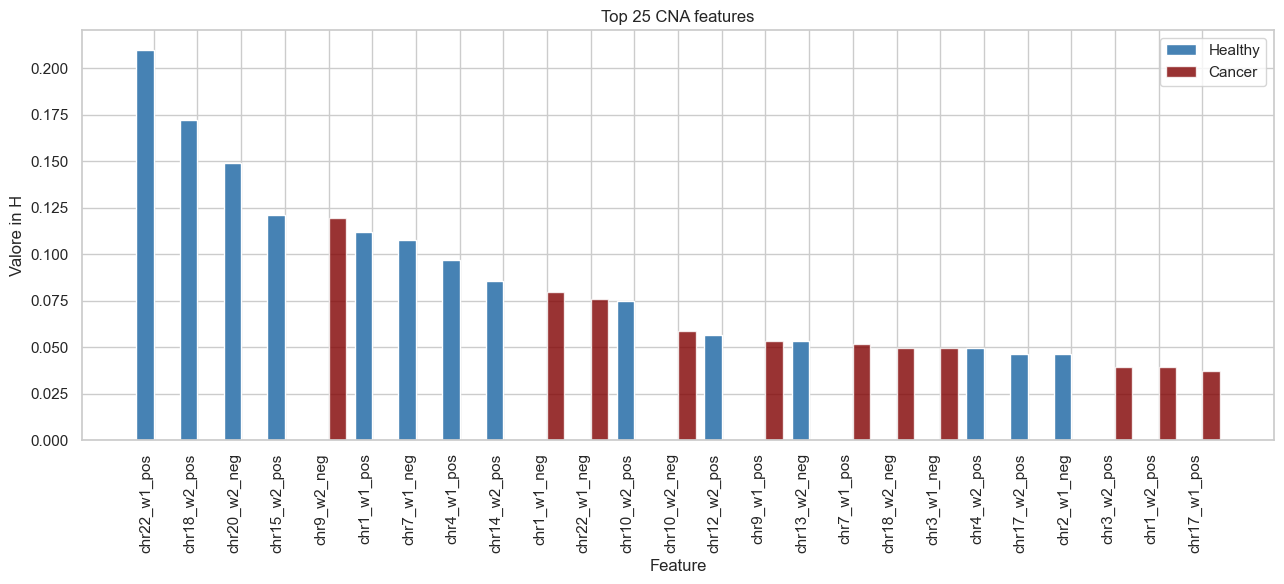

In [1525]:

omic_idx = 1  # secondo dataset: CNA
top_n = 25

# H ha forma: componenti x feature
H = np.asarray(res.Hs[omic_idx])
Hd_0 = np.clip(H[0, :] - H[1, :], a_min = 0, a_max = 1000)
Hd_1 = np.clip(H[1, :] - H[0, :], a_min = 0, a_max = 1000)
H = np.concatenate((Hd_0, Hd_1), axis=0).reshape(2, 84)
# Rimuovi dai nomi le feature costanti rimosse prima del fit.
feature_names = cna_signed.columns.drop([
    "chr13_w1_pos", "chr14_w1_pos",
    "chr13_w1_neg", "chr14_w1_neg",
]).to_numpy()

if H.shape[1] != len(feature_names):
    raise ValueError("Il numero di nomi feature non corrisponde alle colonne di H.")
if H.shape[0] < 2:
    raise ValueError("H deve contenere almeno due componenti.")

# Prende le feature più rappresentate in almeno una delle due componenti.
top_idx = np.argsort(H[:2].max(axis=0))[::-1][:top_n]
x = np.arange(len(top_idx))
width = 0.4

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width / 2, H[0, top_idx], width, label="Healthy", color='steelblue')
ax.bar(x + width / 2, H[1, top_idx], width, label="Cancer", color='maroon', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(feature_names[top_idx], rotation=90, ha="right")
ax.set_xlabel("Feature")
ax.set_ylabel("Valore in H")
ax.set_title(f"Top {len(top_idx)} CNA features")
ax.legend()
fig.tight_layout()
plt.show()

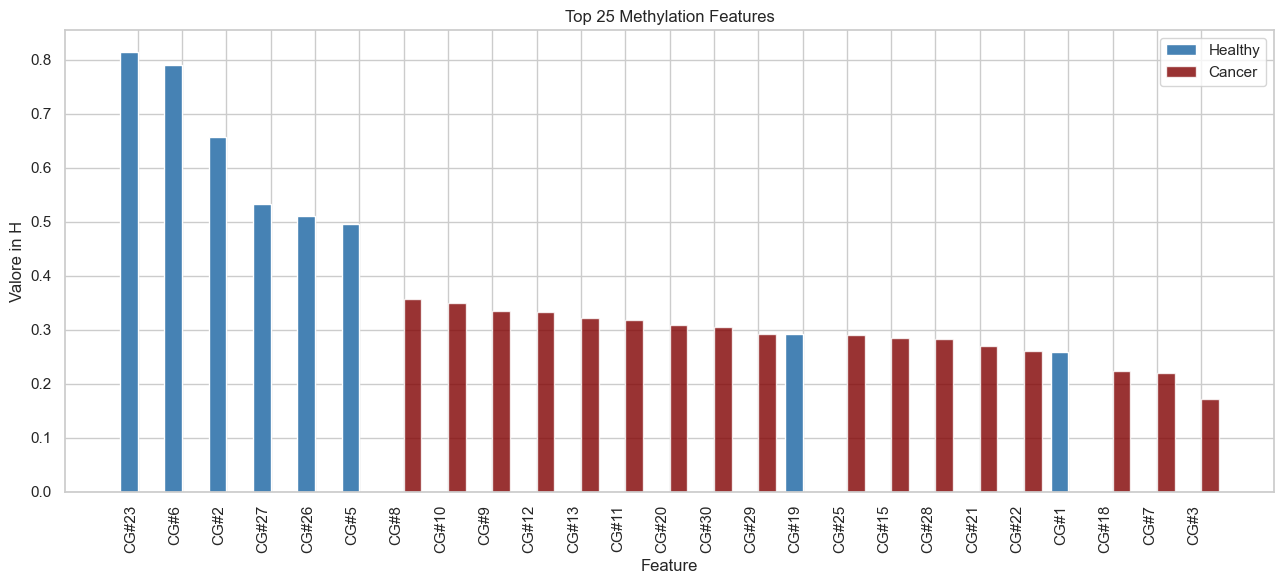

In [1526]:

omic_idx = 0  # first dataset: meth
top_n = 25

# H ha forma: componenti x feature
H = np.asarray(res.Hs[omic_idx])
Hd_0 = np.clip(H[0, :] - H[1, :], a_min = 0, a_max = 1000)
Hd_1 = np.clip(H[1, :] - H[0, :], a_min = 0, a_max = 1000)
H = np.concatenate((Hd_0, Hd_1), axis=0).reshape(2, 30)
#H = (H.T / H.T.max(axis=0)).T
# Rimuovi dai nomi le feature costanti rimosse prima del fit.
feature_names = meth_signed.columns.to_numpy()

if H.shape[1] != len(feature_names):
    raise ValueError("Il numero di nomi feature non corrisponde alle colonne di H.")
if H.shape[0] < 2:
    raise ValueError("H deve contenere almeno due componenti.")

# Prende le feature più rappresentate in almeno una delle due componenti.
top_idx = np.argsort(H[:2].max(axis=0))[::-1][:top_n]
x = np.arange(len(top_idx))
width = 0.4

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(x - width / 2, H[0, top_idx], width, label="Healthy", color='steelblue')
ax.bar(x + width / 2, H[1, top_idx], width, label="Cancer", color='maroon', alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels((feature_names)[top_idx] , rotation=90, ha="right")
ax.set_xlabel("Feature")
ax.set_ylabel("Valore in H")
ax.set_title(f"Top {len(top_idx)} Methylation Features")
ax.legend()
fig.tight_layout()
plt.show()

In [1086]:
proj_0 = safe_sparse_dot(res.omics[0], res.Hs[0].T)
test_0 = safe_sparse_dot(tests[0], res.Hs[0].T)
model_0 = LogisticRegression(l1_ratio=0)
model_0.fit(proj_0, y_train)
y_meth_hat = model_0.predict_proba(proj_0)
y_meth_pred = model_0.predict_proba(test_0)


print("Methylation AUC (train): ", roc_auc_score(y_train, y_meth_hat[:, 1]))
print("Methylation AUC (test): ", roc_auc_score(y_test, y_meth_pred[:, 1]), "\n")
print("Methylation Accuracy (train): ", model_0.score(proj_0, y_train))
print("Methylation Accuracy (test): ", model_0.score(test_0, y_test), "\n")


# model_0 = LogisticRegression()
# model_0.fit(proj_0, y_train)
# y_meth_hat = model_0.predict_proba(proj_0)
# model_1 = LogisticRegression()
# model_1.fit(proj_1, y_train)
# y_cna_hat = model_1.predict_proba(proj_1)


# test_0 = safe_sparse_dot(tests[0], res.Hs[0].T)
# test_1 = safe_sparse_dot(tests[1], res.Hs[1].T)

# y_meth_pred = model_0.predict_proba(test_0)
# y_cna_pred = model_1.predict_proba(test_1)


# print("Methylation AUC (train): ", roc_auc_score(y_train, y_meth_hat[:, 1]))
# print("Methylation AUC (test): ", roc_auc_score(y_test, y_meth_pred[:, 1]), "\n")
# print("Methylation Accuracy (train): ", model_0.score(proj_0, y_train))
# print("Methylation Accuracy (test): ", model_0.score(test_0, y_test), "\n")
# print("CNA AUC (train): ", roc_auc_score(y_train, y_cna_hat[:, 1]))
# print("CNA AUC (test): ", roc_auc_score(y_test, y_cna_pred[:, 1]), "\n")
# print("CNA Accuracy (train): ", model_1.score(proj_1, y_train))
# print("CNA Accuracy (test): ", model_1.score(test_1, y_test), "\n")



Methylation AUC (train):  0.9765130984643179
Methylation AUC (test):  1.0 

Methylation Accuracy (train):  0.8631578947368421
Methylation Accuracy (test):  0.8636363636363636 



In [1000]:
proj_0 = safe_sparse_dot(X1_train, res.Hs[0].T)
proj_1 = safe_sparse_dot(X2_train, res.Hs[1].T)

model_0 = RandomForestClassifier()
model_0.fit(proj_0, y_train)
y_meth_hat = model_0.predict_proba(proj_0)
model_1 = RandomForestClassifier()
model_1.fit(proj_1, y_train)
y_cna_hat = model_1.predict_proba(proj_1)

test_0 = safe_sparse_dot(X1_test , H_meth.T)
test_1 = safe_sparse_dot(X2_test, H_cna.T)

y_meth_pred = model_0.predict_proba(test_0)
y_cna_pred = model_1.predict_proba(test_1)


print("Methylation AUC (train): ", roc_auc_score(y_train, y_meth_hat[:, 1]))
print("Methylation AUC (test): ", roc_auc_score(y_test, y_meth_pred[:, 1]), "\n")
print("Methylation Accuracy (train): ", model_0.score(proj_0, y_train))
print("Methylation Accuracy (test): ", model_0.score(test_0, y_test), "\n")
print("CNA AUC (train): ", roc_auc_score(y_train, y_cna_hat[:, 1]))
print("CNA AUC (test): ", roc_auc_score(y_test, y_cna_pred[:, 1]), "\n")
print("CNA Accuracy (train): ", model_1.score(proj_1, y_train))
print("CNA Accuracy (test): ", model_1.score(test_1, y_test), "\n")


Methylation AUC (train):  1.0
Methylation AUC (test):  0.9824561403508772 

Methylation Accuracy (train):  1.0
Methylation Accuracy (test):  0.9534883720930233 

CNA AUC (train):  1.0
CNA AUC (test):  0.9649122807017544 

CNA Accuracy (train):  1.0
CNA Accuracy (test):  0.9069767441860465 



In [961]:
model = NMFProfiler(
    omics=[X2_train],
    y=y_train,
    as_sklearn=True,
    params={
                "gamma":1e-3,
                "lambda": 1e-7,
                "mu": 1e-7,
                "eta": 1.00,
                "alpha": 2,
                "sigma": 1e-9,
                "m_back": 1,
            },
    backtrack=True,
    verbose=False)

res = model.fit()

tests = [X2_test]
# for j in range(len(tests)):
#     for i in range(tests[j].shape[1]):
#         tests[j][:, i] = (
#             tests[j][:, i] - np.min(tests[j][:, i])
#         ) / (
#             np.max(tests[j][:, i]) - np.min(tests[j][:, i])
#         )
#     tests[j] = (
#         tests[j] * (1 / np.sqrt(tests[j].shape[1]))
#     )



H_cna = res.Hs[0]



proj_1 = safe_sparse_dot(X2_train, res.Hs[0].T)



model_1 = LogisticRegression()
model_1.fit(proj_1, y_train)
y_cna_hat = model_1.predict_proba(proj_1)

test_1 = safe_sparse_dot(tests[0], H_cna.T)
y_cna_pred = model_1.predict_proba(test_1)


# 2. Calcola FPR, TPR e le relative soglie (thresholds)
fpr, tpr, thresholds = roc_curve(y_test, y_cna_pred[:, 1])

# 3. Trova l'indice in cui la specificità (1 - fpr) è >= 0.99
# Questo equivale a cercare fpr <= 0.01
target_specificity = 0.5
target_fpr = 1 - target_specificity  # 0.01

# Prendi l'ultima soglia (più bassa) che garantisce ancora fpr <= 0.01
valid_indices = np.where(fpr <= target_fpr)[0]
best_idx = valid_indices[-1]
best_threshold = thresholds[best_idx]

# 4. Applica la nuova soglia per ottenere le predizioni binarie
y_pred_custom = (y_cna_pred >= best_threshold).astype(int)[:, 1]

# 5. Calcola la nuova accuracy e verifica la specificità ottenuta
custom_accuracy = accuracy_score(y_test, y_pred_custom)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_custom).ravel()
actual_specificity = tn / (tn + fp)




print("CNA AUC (train): ", roc_auc_score(y_train, y_cna_hat[:, 1]))
print("CNA AUC (test): ", roc_auc_score(y_test, y_cna_pred[:, 1]), "\n")
print("CNA Accuracy (train): ", model_1.score(proj_1, y_train))
print("CNA Accuracy (test): ", custom_accuracy, "\n")



CNA AUC (train):  0.8533105022831051
CNA AUC (test):  0.9232456140350878 

CNA Accuracy (train):  0.8224852071005917
CNA Accuracy (test):  0.7209302325581395 



In [962]:
X2.sum()

np.float64(12305.20954043166)

In [1532]:
def cross_validation(X1_tr, X1_te, X2_tr, X2_te, y_tr, y_te, multi = True, verbose = False):

    tests = [X1_te, X2_te]
    
    if multi:
        omics = [X1_tr, X2_tr]
        for j in range(2):
            for i in range(omics[j].shape[1]):
                tests[j][:, i] = (
                                    tests[j][:, i] - np.min(omics[j][:, i])
                                ) / (
                                    np.max(omics[j][:, i]) - np.min(omics[j][:, i])
                                )
                omics[j][:, i] = (
                    omics[j][:, i] - np.min(omics[j][:, i])
                ) / (
                    np.max(omics[j][:, i]) - np.min(omics[j][:, i])
                )
                
            omics[j] = (
                omics[j] * (1 / np.sqrt(omics[j].shape[1]))
            )
            tests[j] = tests[j] * (1 / np.sqrt(omics[j].shape[1]))
           
    else:
        omics = [X1_tr]
        


    
    model = NMFProfiler(
    omics=omics,
    y=y_tr,
    as_sklearn=True,
    # params={
    #             "gamma": 1e-4,
    #             "lambda": 1e-6,
    #             "mu": 1e-6,
    #             "eta": 1.00,
    #             "alpha": 2,
    #             "sigma": 1e-9,
    #             "m_back": 1,
    #         },
    backtrack=True,
    verbose=False)

    res = model.fit()

    

    proj_0 = safe_sparse_dot(res.omics[0], res.Hs[0].T)
    test_0 = safe_sparse_dot(tests[0], res.Hs[0].T)
    model_0 = LogisticRegression(l1_ratio=0)
    model_0.fit(proj_0, y_tr)
    y_meth_hat = model_0.predict_proba(proj_0)
    y_meth_pred = model_0.predict_proba(test_0)

    # 2. Calcola FPR, TPR e le relative soglie (thresholds)
    fpr, tpr, thresholds = roc_curve(y_test, y_meth_pred[:, 1])

    # 3. Trova l'indice in cui la specificità (1 - fpr) è >= 0.99
    # Questo equivale a cercare fpr <= 0.01
    target_specificity = 0.90
    target_fpr = 1 - target_specificity  # 0.01

    # Prendi l'ultima soglia (più bassa) che garantisce ancora fpr <= 0.01
    valid_indices = np.where(fpr <= target_fpr)[0]
    best_idx = valid_indices[-1]
    best_threshold = thresholds[best_idx]

    # 4. Applica la nuova soglia per ottenere le predizioni binarie
    y_pred_custom = (y_meth_pred >= best_threshold).astype(int)[:, 1]

    # 5. Calcola la nuova accuracy e verifica la specificità ottenuta
    custom_accuracy_m = accuracy_score(y_test, y_pred_custom)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_custom).ravel()
    actual_specificity = tn / (tn + fp)


    
    if multi:
        proj_1 = safe_sparse_dot(res.omics[1], res.Hs[1].T)
        test_1 = safe_sparse_dot(tests[1], res.Hs[1].T)    
        
        model_1 = LogisticRegression(l1_ratio=0)
        model_1.fit(proj_1, y_tr)
        y_cna_hat = model_1.predict_proba(proj_1)  
        y_cna_pred = model_1.predict_proba(test_1)

        # 2. Calcola FPR, TPR e le relative soglie (thresholds)
        fpr, tpr, thresholds = roc_curve(y_test, y_cna_pred[:, 1])
    
        # 3. Trova l'indice in cui la specificità (1 - fpr) è >= 0.99
        # Questo equivale a cercare fpr <= 0.01
        target_specificity = 0.90
        target_fpr = 1 - target_specificity  # 0.01
    
        # Prendi l'ultima soglia (più bassa) che garantisce ancora fpr <= 0.01
        valid_indices = np.where(fpr <= target_fpr)[0]
        best_idx = valid_indices[-1]
        best_threshold = thresholds[best_idx]
    
        # 4. Applica la nuova soglia per ottenere le predizioni binarie
        y_pred_custom = (y_cna_pred >= best_threshold).astype(int)[:, 1]
    
        # 5. Calcola la nuova accuracy e verifica la specificità ottenuta
        custom_accuracy_c = accuracy_score(y_test, y_pred_custom)
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred_custom).ravel()
        actual_specificity = tn / (tn + fp)
        #print(y_meth_pred)
    
    if verbose:
        print("Methylation AUC (train): ", roc_auc_score(y_tr, y_meth_hat[:, 1]))
        print("Methylation AUC (test): ", roc_auc_score(y_te, y_meth_pred[:, 1]), "\n")
        print("Methylation Accuracy (train): ", model_0.score(proj_0, y_tr))
        print("Methylation Accuracy (test): ", custom_accuracy_m, "\n")
        if multi:
            print("CNA AUC (train): ", roc_auc_score(y_tr, y_cna_hat[:, 1]))
            print("CNA AUC (test): ", roc_auc_score(y_te, y_cna_pred[:, 1]), "\n")
            print("CNA Accuracy (train): ", model_1.score(proj_1, y_tr))
            print("CNA Accuracy (test): ", custom_accuracy_c, "\n")
        
    if multi:
        return roc_auc_score(y_te, y_meth_pred[:, 1]), custom_accuracy_m, roc_auc_score(y_te, y_cna_pred[:, 1]), custom_accuracy_c
    else:
        return roc_auc_score(y_te, y_meth_pred[:, 1]), custom_accuracy_m


In [1096]:
X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.1, stratify=y)

cross_validation(X1_train, X1_test, X2_train, X2_test, y_train, y_test, verbose=True, multi=True)

Methylation AUC (train):  0.9926603432700993
Methylation AUC (test):  0.9 

Methylation Accuracy (train):  0.8315789473684211
Methylation Accuracy (test):  0.9545454545454546 

CNA AUC (train):  0.9917570009033424
CNA AUC (test):  1.0 

CNA Accuracy (train):  0.5684210526315789
CNA Accuracy (test):  1.0 



(0.9, 0.9545454545454546, 1.0, 1.0)

In [1533]:
trials = 200
cna_auc_sing = np.zeros(trials) 
meth_auc_sing = np.zeros(trials) 
cna_auc = np.zeros(trials)
meth_auc = np.zeros(trials)
cna_acc_sing = np.zeros(trials)
meth_acc_sing = np.zeros(trials)
cna_acc = np.zeros(trials)
meth_acc = np.zeros(trials)

#rng = np.random.randint(1, 100000, trials)

for i in tqdm(range(trials)):
    X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.2, stratify=y, random_state=  rng[i])
    
    meth_auc[i], meth_acc[i], cna_auc[i], cna_acc[i] = cross_validation(X1_train, X1_test, X2_train, X2_test, y_train, y_test)

for i in tqdm(range(trials)):
    X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.2, stratify=y, random_state=  rng[i])
    meth_auc_sing[i], meth_acc_sing[i] = cross_validation(X1_train, X1_test, X2_train, X2_test, y_train, y_test, multi=False)
    cna_auc_sing[i], cna_acc_sing[i] = cross_validation(X2_train, X2_test, X1_test, X1_train, y_train, y_test, multi=False)
    
   

100%|██████████| 200/200 [01:32<00:00,  2.16it/s]


In [1017]:
rng

array([65071, 75807, 87851, 96096, 84226, 56711, 41174, 72733, 24881,
        8587, 57780, 49761, 23084, 53221, 74392, 86831, 59802, 90037,
       73746, 33455,   997, 15715,  3490, 58572,  9131, 40168, 24997,
       73024, 41983, 54446, 17951, 95797, 96569, 19139, 59828, 21015,
       47140, 42409,   666, 59187, 75023, 55376, 46945, 67003,  6502,
       63263, 58532, 46091, 35067, 59243, 92244,  4331,  6772, 31495,
       66006, 76810, 33015, 88375, 95399, 31623, 93884, 94165, 84251,
       44701, 39035, 95152, 23704, 24622,  7571, 77795, 54274, 98641,
       86189,  8445, 74264, 73275, 43355, 75204, 48026,  2732, 77801,
       47520, 31819, 49284, 55728, 96822, 51457, 66132, 29420, 73749,
       34062, 36808, 36315,  7058, 81046, 49008, 29163, 39669,  9218,
       36637, 59474, 68161, 51297, 41640, 68413, 16680, 45778, 52139,
       93304,  6832, 72436, 95516, 37976, 48538, 42408,  7564, 78526,
       51488, 17619, 16708, 64510, 57782, 89695, 73177, 13957, 37982,
       23793, 84984,

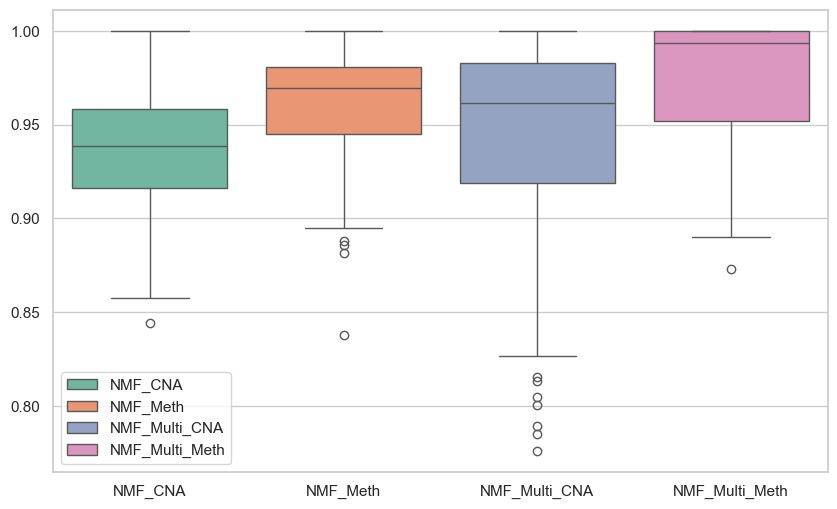

In [1534]:
fig, ax = plt.subplots(figsize = (10, 6))
sns.boxplot([cna_auc_sing, meth_auc_sing, cna_auc, meth_auc], ax = ax, palette=["#71B6A1", '#E99675', '#95A3C3', '#DB96C0'], saturation= 1)
#ax.set_ylim([0.85, 1.05])

#ax.set_label(["NMF_CNA", "NMF_Meth", "NMF_Multi_CNA", "NMF_Multi_Meth"])
ax.set_xticks(range(4))
ax.set_xticklabels(["NMF_CNA", "NMF_Meth", "NMF_Multi_CNA", "NMF_Multi_Meth"])
ax.legend(["NMF_CNA", "NMF_Meth", "NMF_Multi_CNA", "NMF_Multi_Meth"])
plt.show()


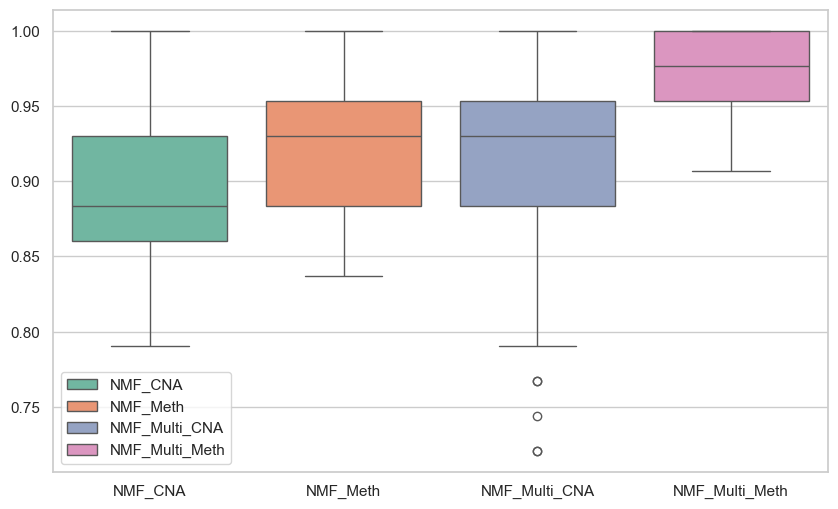

In [1535]:
fig, ax = plt.subplots(figsize = (10, 6))
sns.boxplot([cna_acc_sing, meth_acc_sing, cna_acc, meth_acc], ax = ax, palette=  ["#71B6A1", '#E99675', '#95A3C3', '#DB96C0'], saturation= 1, )
#ax.set_ylim([0.85, 1.05])
ax.set_xticks(range(4))
ax.set_xticklabels(["NMF_CNA", "NMF_Meth", "NMF_Multi_CNA", "NMF_Multi_Meth"])
ax.legend(["NMF_CNA", "NMF_Meth", "NMF_Multi_CNA", "NMF_Multi_Meth"])
plt.show()
plt.show()


In [969]:
def roc(X1_tr, X1_te, X2_tr, X2_te, y_tr, y_te, multi = True, verbose = False):

    tests = [X1_te, X2_te]
    
    if multi:
        omics = [X1_tr, X2_tr]
        for j in range(2):
            for i in range(omics[j].shape[1]):
                omics[j][:, i] = (
                    omics[j][:, i] - np.min(omics[j][:, i])
                ) / (
                    np.max(omics[j][:, i]) - np.min(omics[j][:, i])
                )
                tests[j][:, i] = (
                    tests[j][:, i] - np.min(omics[j][:, i])
                ) / (
                    np.max(omics[j][:, i]) - np.min(omics[j][:, i])
                )
            omics[j] = (
                omics[j] * (1 / np.sqrt(omics[j].shape[1]))
            )
            tests[j] = tests[j] * (1 / np.sqrt(omics[j].shape[1]))
           
    else:
        omics = [X1_tr]
        


    
    model = NMFProfiler(
    omics=omics,
    y=y_tr,
    as_sklearn=True,
    params={
                "gamma": 1e-4,
                "lambda": 1e-6,
                "mu": 1e-6,
                "eta": 1.00,
                "alpha": 2,
                "sigma": 1e-9,
                "m_back": 1,
            },
    backtrack=True,
    verbose=False)

    res = model.fit()

    

    proj_0 = safe_sparse_dot(res.omics[0], res.Hs[0].T)
    test_0 = safe_sparse_dot(tests[0], res.Hs[0].T)
    model_0 = LogisticRegression(l1_ratio=0)
    model_0.fit(proj_0, y_tr)
    y_meth_hat = model_0.predict_proba(proj_0)
    y_meth_pred = model_0.predict_proba(test_0)

    # 2. Calcola FPR, TPR e le relative soglie (thresholds)
    fpr_0, tpr_0, thresholds = roc_curve(y_test, y_meth_pred[:, 1])
    
    if multi:
            proj_1 = safe_sparse_dot(res.omics[1], res.Hs[1].T)
            test_1 = safe_sparse_dot(tests[1], res.Hs[1].T)    
            
            model_1 = LogisticRegression(l1_ratio=0)
            model_1.fit(proj_1, y_tr)
            y_cna_hat = model_1.predict_proba(proj_1)  
            y_cna_pred = model_1.predict_proba(test_1)
    
            # 2. Calcola FPR, TPR e le relative soglie (thresholds)
            fpr_1, tpr_1, thresholds = roc_curve(y_test, y_cna_pred[:, 1])

    if verbose:
        print("Methylation AUC (train): ", roc_auc_score(y_tr, y_meth_hat[:, 1]))
        print("Methylation AUC (test): ", roc_auc_score(y_te, y_meth_pred[:, 1]), "\n")
        print("Methylation Accuracy (train): ", model_0.score(proj_0, y_tr))
        print("Methylation Accuracy (test): ", model_0.score(test_0, y_te ), "\n")
        if multi:
            print("CNA AUC (train): ", roc_auc_score(y_tr, y_cna_hat[:, 1]))
            print("CNA AUC (test): ", roc_auc_score(y_te, y_cna_pred[:, 1]), "\n")
            print("CNA Accuracy (train): ", model_1.score(proj_1, y_tr))
            print("CNA Accuracy (test): ", model_1.score(test_1, y_te), "\n")
        
    if multi:
        return fpr_0, tpr_0, fpr_1, tpr_1
    else:
        return fpr_0, tpr_0


  9%|▉         | 9/100 [00:02<00:27,  3.26it/s]/opt/anaconda3/lib/python3.12/site-packages/nmfprofiler/nmfprofiler.py:1263: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(
 14%|█▍        | 14/100 [00:04<00:31,  2.74it/s]/opt/anaconda3/lib/python3.12/site-packages/nmfprofiler/nmfprofiler.py:1263: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(
 17%|█▋        | 17/100 [00:06<00:34,  2.40it/s]/opt/anaconda3/lib/python3.12/site-packages/nmfprofiler/nmfprofiler.py:1263: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(
 38%|███▊      | 38/100 [00:13<00:22,  2.78it/s]/opt/anaconda3/lib/python3.12/site-packages/nmfprofiler/nmfprofiler.py:1263: ConvergenceWarning: Maximum number of iterations 1000 reached. Increase it to improve convergence.
  warnings.warn(
 40%|████      | 40/100 [00:14<00:28,

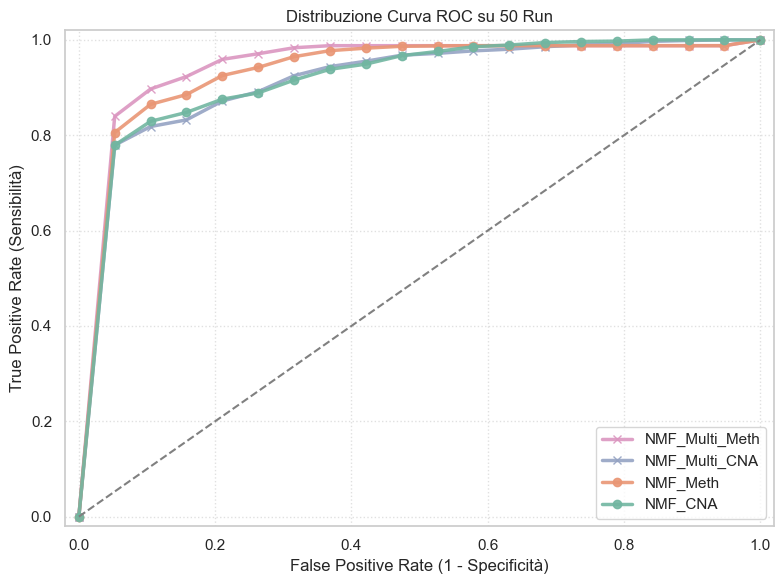

In [970]:
from sklearn.metrics import auc
trials = 100
auc_meth = []
tpr_meth = []
auc_cna = []
tpr_cna = []
auc_meth_s = []
tpr_meth_s = []
auc_cna_s = []
tpr_cna_s = []

fig, ax = plt.subplots(figsize=(8, 6))
mean_fpr = np.linspace(0, 1, 20)

for i in tqdm(range(trials)):
    X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.25, stratify=y, random_state=  rng[i])
    
    fpr_0, tpr_0, fpr_1, tpr_1 = roc(X1_train, X1_test, X2_train, X2_test, y_train, y_test)
    roc_auc = auc(fpr_0, tpr_0)
    auc_meth.append(roc_auc)
    roc_auc = auc(fpr_1, tpr_1)
    auc_cna.append(roc_auc)
    interp_tpr = np.interp(mean_fpr, fpr_0, tpr_0)
    interp_tpr[0] = 0.0
    tpr_meth.append(interp_tpr)
    interp_tpr = np.interp(mean_fpr, fpr_1, tpr_1)
    interp_tpr[0] = 0.0
    tpr_cna.append(interp_tpr)
    # Plotta il singolo run molto trasparente (spaghetti plot)
    #ax.plot(fpr_0, tpr_0, color='#DB96C0', alpha=0.12, lw=1)
    #ax.plot(fpr_1, tpr_1, color =  '#95A3C3')

mean_tpr_meth = np.mean(tpr_meth, axis=0)
mean_tpr_meth[-1] = 1.0
mean_tpr_cna = np.mean(tpr_cna, axis=0)
mean_tpr_cna[-1] = 1.0
mean_auc_meth = auc(mean_fpr, mean_tpr_meth)
std_auc_meth = np.std(auc_meth)
mean_auc_cna = auc(mean_fpr, mean_tpr_cna)
std_auc_meth = np.std(auc_cna)

std_tpr_meth = np.std(tpr_meth, axis=0)
std_tpr_cna= np.std(tpr_cna, axis=0)
tprs_upper = np.minimum(mean_tpr_meth + std_tpr_meth, 1)
tprs_lower = np.maximum(mean_tpr_meth - std_tpr_meth, 0)

# 3. Plot della curva media e della fascia di deviazione standard
ax.plot(mean_fpr, mean_tpr_meth, color='#DB96C0',
        lw=2.5, alpha=0.9, marker = "x")
# ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color='#DB96C0', alpha=0.25,
#                 label='± 1 dev. std.')
# Linea di riferimento (classificatore casuale)
# 3. Plot della curva media e della fascia di deviazione standard
tprs_upper = np.minimum(mean_tpr_cna + std_tpr_cna, 1)
tprs_lower = np.maximum(mean_tpr_cna - std_tpr_cna, 0)
ax.plot(mean_fpr, mean_tpr_cna, color='#95A3C3',
        lw=2.5, alpha=0.9, marker = "x")
# ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color='#95A3C3', alpha=0.25,
#                 label='± 1 dev. std.')


for i in tqdm(range(trials)):
    X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.25, stratify=y, random_state=  rng[i])
    
    fpr_0, tpr_0 = roc(X1_train, X1_test, X2_train, X2_test, y_train, y_test, multi = False)
    fpr_1, tpr_1 = roc(X2_train, X2_test, X1_train, X1_test, y_train, y_test, multi = False)
    roc_auc = auc(fpr_0, tpr_0)
    auc_meth_s.append(roc_auc)
    roc_auc = auc(fpr_1, tpr_1)
    auc_cna_s.append(roc_auc)
    interp_tpr = np.interp(mean_fpr, fpr_0, tpr_0)
    interp_tpr[0] = 0.0
    tpr_meth_s.append(interp_tpr)
    interp_tpr = np.interp(mean_fpr, fpr_1, tpr_1)
    interp_tpr[0] = 0.0
    tpr_cna_s.append(interp_tpr)

mean_tpr_meth = np.mean(tpr_meth_s, axis=0)
mean_tpr_meth[-1] = 1.0
mean_tpr_cna = np.mean(tpr_cna_s, axis=0)
mean_tpr_cna[-1] = 1.0
mean_auc_meth = auc(mean_fpr, mean_tpr_meth)
std_auc_meth = np.std(auc_meth_s)
mean_auc_cna = auc(mean_fpr, mean_tpr_cna)
std_auc_meth = np.std(auc_cna_s)

std_tpr_meth = np.std(tpr_meth, axis=0)
std_tpr_cna= np.std(tpr_cna, axis=0)
tprs_upper = np.minimum(mean_tpr_meth + std_tpr_meth, 1)
tprs_lower = np.maximum(mean_tpr_meth - std_tpr_meth, 0)

# 3. Plot della curva media e della fascia di deviazione standard
ax.plot(mean_fpr, mean_tpr_meth, color='#E99675',
        lw=2.5, alpha=0.9, marker = "o")
# ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color='#E99675', alpha=0.25,
#                 label='± 1 dev. std.')
# Linea di riferimento (classificatore casuale)
# 3. Plot della curva media e della fascia di deviazione standard
tprs_upper = np.minimum(mean_tpr_cna + std_tpr_cna, 1)
tprs_lower = np.maximum(mean_tpr_cna - std_tpr_cna, 0)
ax.plot(mean_fpr, mean_tpr_cna, color="#71B6A1",
        lw=2.5, alpha=0.9, marker = "o")
# ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color="#71B6A1", alpha=0.25,
#                 label='± 1 dev. std.')


ax.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='gray', label='Casuale (AUC = 0.50)')

# Formattazione del grafico
ax.set(xlim=[-0.02, 1.02], ylim=[-0.02, 1.02],
       xlabel='False Positive Rate (1 - Specificità)',
       ylabel='True Positive Rate (Sensibilità)',
       title='Distribuzione Curva ROC su 50 Run')
ax.legend([ "NMF_Multi_Meth", "NMF_Multi_CNA", "NMF_Meth", "NMF_CNA",])
ax.grid(True, linestyle=':', alpha=0.6)


plt.tight_layout()
plt.show()





# for i in tqdm(range(trials)):
#     X1_train, X1_test, X2_train, X2_test, y_train, y_test = train_test_split(X1, X2, y, test_size=0.2, stratify=y, random_state=  rng[i])
#     meth_auc_sing[i], meth_acc_sing[i] = cross_validation(X1_train, X1_test, X2_train, X2_test, y_train, y_test, multi=False)
#     cna_auc_sing[i], cna_acc_sing[i] = cross_validation(X2_train, X2_test, X1_test, X1_train, y_train, y_test, multi=False)

In [971]:
y_test

array([0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 1, 1, 0])

In [1058]:
np.concatenate((omics[0], tests[0])).shape

(212, 30)

In [1057]:
X1.shape

(212, 30)

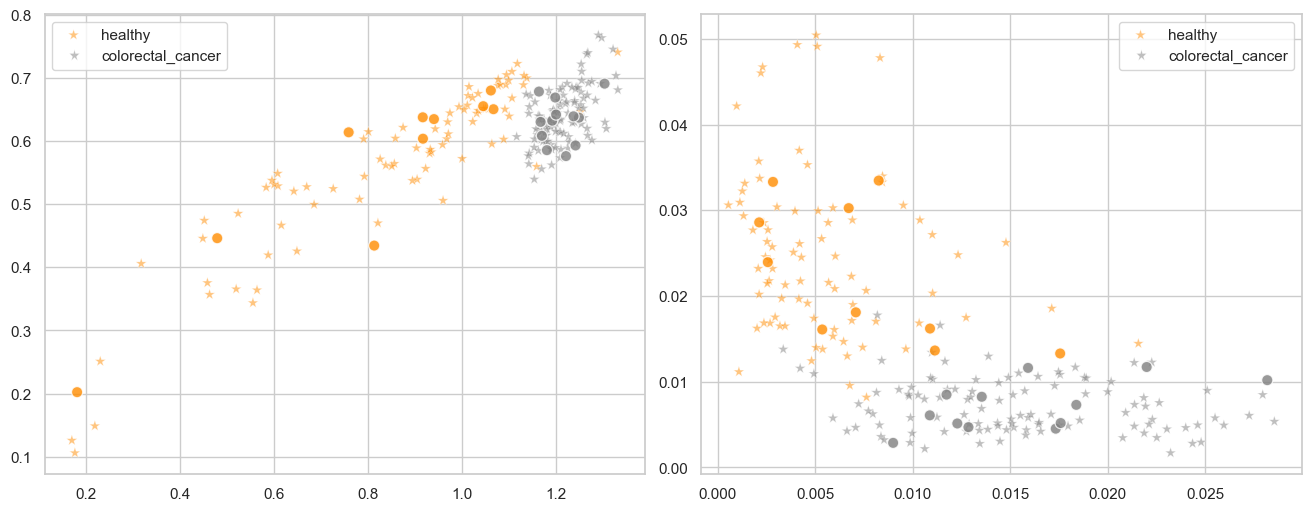

In [1094]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

panels = [
    (axes[0], safe_sparse_dot((omics[0]), res.Hs[0].T), "Methylation — Discovery"),
    (axes[1], safe_sparse_dot((omics[1]), res.Hs[1].T), "CNA — Discovery"),
]

for ax, scores, title in panels:
    sns.scatterplot(
        x=scores[:, 0],
        y=scores[:, 1],
        hue=y_train,
        #hue_order=["healthy", "colorectal_cancer"],
        #palette=palette,
        s=65,
        alpha=0.5,
        edgecolor="white",
        linewidth=0.4,
        ax=ax,
        palette = ["grey", "darkorange"],
        marker = "*"
    )

    ax.legend(["healthy", "colorectal_cancer"])


#sns.despine()


panels = [
    (axes[0], safe_sparse_dot((tests[0]), res.Hs[0].T), "Methylation — Discovery"),
    (axes[1], safe_sparse_dot((tests[1]), res.Hs[1].T), "CNA — Discovery"),
]

for ax, scores, title in panels:
    sns.scatterplot(
        x=scores[:, 0],
        y=scores[:, 1],
        hue=y_test,
        #hue_order=["healthy", "colorectal_cancer"],
        #palette=palette,
        s=65,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.9,
        ax=ax,
        palette = ["grey", "darkorange"],
        marker = "o"
    )

    ax.legend(["healthy", "colorectal_cancer"])


#sns.despine()
plt.show()


In [1075]:
tests[0] @ res.Hs[0].T

array([[0.54360566, 0.56353842],
       [0.70432207, 0.63894097],
       [0.74660092, 0.65291573],
       [0.68439334, 0.62826942],
       [0.72939384, 0.62409345],
       [0.68977868, 0.63176706],
       [0.72224536, 0.60775268],
       [0.75080305, 0.63929024],
       [0.57713099, 0.59198651],
       [0.62538986, 0.61092353],
       [0.64993211, 0.59882666],
       [0.72081286, 0.63750189],
       [0.73184219, 0.63921192],
       [0.58724946, 0.58294203],
       [0.71603605, 0.64248131],
       [0.57594667, 0.59217057],
       [0.74238084, 0.63460002],
       [0.68578771, 0.6311986 ],
       [0.7486313 , 0.63487333],
       [0.74112812, 0.63778232],
       [0.71889098, 0.62677593],
       [0.73255199, 0.63651378]])

In [ ]:
omics[0] 

array([[0.13318654, 0.1434904 , 0.1492479 , ..., 0.10300751, 0.08605768,
        0.0804881 ],
       [0.13135991, 0.15248371, 0.14674345, ..., 0.10530948, 0.12391542,
        0.13034014],
       [0.14110927, 0.1526629 , 0.14806474, ..., 0.10404774, 0.08866164,
        0.08736246],
       ...,
       [0.14405078, 0.15465182, 0.15293485, ..., 0.10215627, 0.07296814,
        0.07800719],
       [0.14934408, 0.15907325, 0.1575022 , ..., 0.12951845, 0.11755241,
        0.11853643],
       [0.13892207, 0.15184478, 0.15799893, ..., 0.09067761, 0.1151479 ,
        0.1273875 ]])